In [1]:

import torch
import platform

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Python: 3.13.16
PyTorch: 2.11.0+cpu
CUDA available: False
Selected device: cpu


In [2]:

%pip -q install -U transformers datasets accelerate evaluate scikit-learn pandas matplotlib seaborn sentencepiece


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 6.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 97.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 27.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 105.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 100.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 103.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 11.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.


In [3]:

import random
import numpy as np
import pandas as pd
import torch

from datasets import load_dataset
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Environment ready!")


Environment ready!


In [9]:

import os
import json
import requests
import tarfile
from datasets import Dataset, DatasetDict

url = (
    "https://amazon-massive-nlu-dataset.s3.amazonaws.com/"
    "amazon-massive-dataset-1.0.tar.gz"
)

archive = "/content/massive.tar.gz"

if not os.path.exists(archive):
    print("Downloading MASSIVE dataset...")
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(archive, "wb") as f:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)

print("Extracting dataset...")

with tarfile.open(archive, "r:gz") as tar:
    tar.extractall(
        path="/content",
        filter="data"
    )

languages = {
    "English": "en-US",
    "Urdu": "ur-PK",
    "Bengali": "bn-BD"
}

datasets_by_language = {}

for language, code in languages.items():
    path = f"/content/1.0/data/{code}.jsonl"

    with open(path, "r", encoding="utf-8") as f:
        records = [json.loads(line) for line in f]

    splits = {}

    for split in ["train", "dev", "test"]:
        selected = [
            {
                "utt": row["utt"],
                "intent": row["intent"],
                "id": row["id"]
            }
            for row in records
            if row["partition"] == split
        ]

        split_name = (
            "validation" if split == "dev" else split
        )

        splits[split_name] = Dataset.from_list(selected)

    datasets_by_language[language] = DatasetDict(splits)

    print(language, {
        name: len(data)
        for name, data in splits.items()
    })

print("\nDataset preparation complete!")


Extracting dataset...
English {'train': 11514, 'validation': 2033, 'test': 2974}
Urdu {'train': 11514, 'validation': 2033, 'test': 2974}
Bengali {'train': 11514, 'validation': 2033, 'test': 2974}

Dataset preparation complete!


In [10]:

for language, dataset in datasets_by_language.items():
    print(f"\n===== {language} =====")

    for split in ["train", "validation", "test"]:
        print(split, ":", len(dataset[split]))

    print("Columns:", dataset["train"].column_names)
    print("Example:", dataset["train"][0])



===== English =====
train : 11514
validation : 2033
test : 2974
Columns: ['utt', 'intent', 'id']
Example: {'utt': 'wake me up at nine am on friday', 'intent': 'alarm_set', 'id': '1'}

===== Urdu =====
train : 11514
validation : 2033
test : 2974
Columns: ['utt', 'intent', 'id']
Example: {'utt': 'مجھے جمعہ کی صبح نو بجے جگا دیں', 'intent': 'alarm_set', 'id': '1'}

===== Bengali =====
train : 11514
validation : 2033
test : 2974
Columns: ['utt', 'intent', 'id']
Example: {'utt': 'আমাকে শুক্রবার সকাল ন-টায় জাগিয়ে দেবেন', 'intent': 'alarm_set', 'id': '1'}


In [11]:

# Extract intent labels from each language
intent_sets = {}

for language, dataset in datasets_by_language.items():
    intents = set(dataset["train"]["intent"])
    intent_sets[language] = intents
    print(f"{language}: {len(intents)} intents")

# Check consistency
assert (
    intent_sets["English"]
    == intent_sets["Urdu"]
    == intent_sets["Bengali"]
), "Intent labels differ across languages!"

print("\nAll languages share the same intent classes!")

# Create numeric label mappings
intent_names = sorted(intent_sets["English"])

label2id = {
    label: idx
    for idx, label in enumerate(intent_names)
}

id2label = {
    idx: label
    for label, idx in label2id.items()
}

num_labels = len(intent_names)

print("Number of labels:", num_labels)
print("First 10 labels:", intent_names[:10])


English: 60 intents
Urdu: 60 intents
Bengali: 60 intents

All languages share the same intent classes!
Number of labels: 60
First 10 labels: ['alarm_query', 'alarm_remove', 'alarm_set', 'audio_volume_down', 'audio_volume_mute', 'audio_volume_other', 'audio_volume_up', 'calendar_query', 'calendar_remove', 'calendar_set']


In [12]:

for split in ["train", "validation", "test"]:
    english_ids = set(
        datasets_by_language["English"][split]["id"]
    )
    urdu_ids = set(
        datasets_by_language["Urdu"][split]["id"]
    )
    bengali_ids = set(
        datasets_by_language["Bengali"][split]["id"]
    )

    assert english_ids == urdu_ids == bengali_ids, (
        f"IDs do not match in {split}"
    )

    print(f"{split}: IDs aligned across languages")

# Verify intent consistency for matching IDs
for split in ["train", "validation", "test"]:
    reference = {
        row["id"]: row["intent"]
        for row in datasets_by_language["English"][split]
    }

    for language in ["Urdu", "Bengali"]:
        for row in datasets_by_language[language][split]:
            assert reference[row["id"]] == row["intent"], (
                f"Intent mismatch: {language}, ID {row['id']}"
            )

print("\nMultilingual alignment verified!")


train: IDs aligned across languages
validation: IDs aligned across languages
test: IDs aligned across languages

Multilingual alignment verified!


In [13]:

from transformers import AutoTokenizer

MODEL_NAME = "bert-base-multilingual-cased"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

sample_text = "مجھے جمعہ کی صبح نو بجے جگا دیں"

encoded = tokenizer(
    sample_text,
    truncation=True,
    max_length=64
)

print("Original text:", sample_text)
print("Tokens:", tokenizer.tokenize(sample_text))
print("Input IDs:", encoded["input_ids"])


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

Original text: مجھے جمعہ کی صبح نو بجے جگا دیں
Tokens: ['م', '##ج', '##ھے', 'جمع', '##ہ', 'کی', 'ص', '##بح', 'نو', 'ب', '##جے', 'ج', '##گا', 'دی', '##ں']
Input IDs: [101, 788, 13027, 59338, 43867, 11242, 11076, 777, 81574, 59658, 764, 56232, 768, 47238, 12687, 13185, 102]


In [14]:

MAX_LENGTH = 64

def preprocess(examples):
    encoded = tokenizer(
        examples["utt"],
        truncation=True,
        max_length=MAX_LENGTH
    )

    encoded["labels"] = [
        label2id[intent]
        for intent in examples["intent"]
    ]

    return encoded


tokenized_datasets = {}

for language, dataset in datasets_by_language.items():
    tokenized_datasets[language] = dataset.map(
        preprocess,
        batched=True,
        remove_columns=dataset["train"].column_names
    )

    print(f"{language} tokenization completed!")

print("\nExample tokenized record:")
print(tokenized_datasets["Urdu"]["train"][0])


Map:   0%|          | 0/11514 [00:00<?, ? examples/s]

Map:   0%|          | 0/2033 [00:00<?, ? examples/s]

Map:   0%|          | 0/2974 [00:00<?, ? examples/s]

English tokenization completed!


Map:   0%|          | 0/11514 [00:00<?, ? examples/s]

...

Urdu tokenization completed!


Map:   0%|          | 0/11514 [00:00<?, ? examples/s]

Map:   0%|          | 0/2033 [00:00<?, ? examples/s]

Map:   0%|          | 0/2974 [00:00<?, ? examples/s]

Bengali tokenization completed!

Example tokenized record:
{'input_ids': [101, 788, 13027, 59338, 43867, 11242, 11076, 777, 81574, 59658, 764, 56232, 768, 47238, 12687, 13185, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'labels': 2}


In [15]:

from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id
)

print("Model loaded successfully!")
print("Number of intent classes:", num_labels)
print(
    "Total parameters:",
    f"{sum(p.numel() for p in model.parameters()):,}"
)


model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully!
Number of intent classes: 60
Total parameters: 177,899,580


In [16]:

import numpy as np

from sklearn.metrics import accuracy_score, f1_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    }

print("Evaluation metrics ready!")


Evaluation metrics ready!


In [18]:

from transformers import TrainingArguments
import inspect
import torch

print("TrainingArguments module:", TrainingArguments.__module__)
print("Supported arguments:")
print(inspect.signature(TrainingArguments.__init__))

training_args = TrainingArguments(
    output_dir="/content/mbert_english",

    num_train_epochs=3,
    learning_rate=2e-5,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,

    weight_decay=0.01,
    warmup_steps=216,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    fp16=torch.cuda.is_available(),

    logging_steps=100,
    save_total_limit=1,

    seed=42,
    data_seed=42,

    report_to="none"
)

print("Training configuration ready!")


TrainingArguments module: transformers.training_args
Supported arguments:
(self, output_dir: str | None = None, per_device_train_batch_size: int = 8, num_train_epochs: float = 3.0, max_steps: int = -1, learning_rate: float = 5e-05, lr_scheduler_type: transformers.trainer_utils.SchedulerType | str = 'linear', lr_scheduler_kwargs: dict | str | None = None, warmup_steps: float = 0, optim: transformers.training_args.OptimizerNames | str = 'adamw_torch_fused', optim_args: str | None = None, weight_decay: float = 0.0, adam_beta1: float = 0.9, adam_beta2: float = 0.999, adam_epsilon: float = 1e-08, optim_target_modules: None | str | list[str] = None, gradient_accumulation_steps: int = 1, average_tokens_across_devices: bool = True, max_grad_norm: float = 1.0, label_smoothing_factor: float = 0.0, bf16: bool = False, fp16: bool = False, bf16_full_eval: bool = False, fp16_full_eval: bool = False, tf32: bool | None = None, gradient_checkpointing: bool = False, gradient_checkpointing_kwargs: dict[s

In [19]:

from transformers import Trainer, DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

trainer = Trainer(
    model=model,
    args=training_args,

    train_dataset=tokenized_datasets["English"]["train"],
    eval_dataset=tokenized_datasets["English"]["validation"],

    processing_class=tokenizer,
    data_collator=data_collator,

    compute_metrics=compute_metrics
)

print("Trainer initialized!")


Trainer initialized!


In [20]:

print("Starting mBERT fine-tuning...")

train_result = trainer.train()

print("\nTraining completed!")
print(train_result.metrics)


Starting mBERT fine-tuning...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.513448,1.246825,0.755534,0.563444
2,0.792294,0.778551,0.835219,0.706609


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


...

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.513448,1.246825,0.755534,0.563444
2,0.792294,0.778551,0.835219,0.706609
3,0.565771,0.688685,0.845057,0.720725


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte


Training completed!
{'train_runtime': 9828.285, 'train_samples_per_second': 3.515, 'train_steps_per_second': 0.22, 'total_flos': 349825839240096.0, 'train_loss': 1.4036683276847557, 'epoch': 3.0}


In [21]:

import torch
import transformers
import inspect

print("PyTorch version:", torch.__version__)
print("Transformers version:", transformers.__version__)

print("\nGPU diagnostics")
print("CUDA available:", torch.cuda.is_available())
print("CUDA device count:", torch.cuda.device_count())
print("Trainer device:", trainer.args.device)

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

print("\nModel diagnostics")
print("Model device:", next(trainer.model.parameters()).device)
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best metric:", trainer.state.best_metric)

print("\nTrainingArguments module:")
print(inspect.getfile(type(trainer.args)))


PyTorch version: 2.11.0+cpu
Transformers version: 5.19.0

GPU diagnostics
CUDA available: False
CUDA device count: 0
Trainer device: cpu

Model diagnostics
Model device: cpu
Best checkpoint: /content/mbert_english/checkpoint-2160
Best metric: 0.720725224351729

TrainingArguments module:
/usr/local/lib/python3.13/dist-packages/transformers/training_args.py


In [22]:

from google.colab import drive
import shutil
import os

drive.mount("/content/drive")

source = "/content/mbert_english/checkpoint-2160"

destination = (
    "/content/drive/MyDrive/"
    "CrossLingual_AI/mbert_checkpoint"
)

os.makedirs(
    os.path.dirname(destination),
    exist_ok=True
)

shutil.copytree(
    source,
    destination,
    dirs_exist_ok=True
)

print("Checkpoint saved to Google Drive!")
print("Location:", destination)
print("Files:", os.listdir(destination))


Mounted at /content/drive
Checkpoint saved to Google Drive!
Location: /content/drive/MyDrive/CrossLingual_AI/mbert_checkpoint
Files: ['trainer_state.json', 'optimizer.pt', 'scheduler.pt', 'rng_state.pth', 'config.json', 'tokenizer_config.json', 'training_args.bin', 'tokenizer.json', 'model.safetensors']


In [23]:

from safetensors import safe_open
import os

checkpoint = (
    "/content/drive/MyDrive/"
    "CrossLingual_AI/mbert_checkpoint"
)

model_file = os.path.join(
    checkpoint,
    "model.safetensors"
)

with safe_open(
    model_file,
    framework="pt",
    device="cpu"
) as f:
    keys = list(f.keys())

layernorm_keys = [
    key for key in keys
    if "LayerNorm" in key
]

gamma_beta = [
    key for key in layernorm_keys
    if key.endswith((".gamma", ".beta"))
]

weight_bias = [
    key for key in layernorm_keys
    if key.endswith((".weight", ".bias"))
]

print("Total model tensors:", len(keys))
print("LayerNorm tensors:", len(layernorm_keys))
print("Gamma/Beta tensors:", len(gamma_beta))
print("Weight/Bias tensors:", len(weight_bias))

print("\nSample LayerNorm keys:")
for key in layernorm_keys[:10]:
    print(key)


Total model tensors: 201
LayerNorm tensors: 50
Gamma/Beta tensors: 50
Weight/Bias tensors: 0

Sample LayerNorm keys:
bert.embeddings.LayerNorm.beta
bert.embeddings.LayerNorm.gamma
bert.encoder.layer.0.attention.output.LayerNorm.beta
bert.encoder.layer.0.attention.output.LayerNorm.gamma
bert.encoder.layer.0.output.LayerNorm.beta
bert.encoder.layer.0.output.LayerNorm.gamma
bert.encoder.layer.1.attention.output.LayerNorm.beta
bert.encoder.layer.1.attention.output.LayerNorm.gamma
bert.encoder.layer.1.output.LayerNorm.beta
bert.encoder.layer.1.output.LayerNorm.gamma


In [24]:

import os
import shutil
from safetensors import safe_open
from safetensors.torch import save_file

source_dir = (
    "/content/drive/MyDrive/"
    "CrossLingual_AI/mbert_checkpoint"
)

fixed_dir = (
    "/content/drive/MyDrive/"
    "CrossLingual_AI/mbert_checkpoint_fixed"
)

os.makedirs(fixed_dir, exist_ok=True)

# Copy model configuration and tokenizer files
for filename in [
    "config.json",
    "tokenizer_config.json",
    "tokenizer.json"
]:
    source_file = os.path.join(source_dir, filename)

    if os.path.exists(source_file):
        shutil.copy2(
            source_file,
            os.path.join(fixed_dir, filename)
        )

source_model = os.path.join(
    source_dir, "model.safetensors"
)

fixed_weights = {}
renamed_count = 0

with safe_open(
    source_model,
    framework="pt",
    device="cpu"
) as f:

    for key in f.keys():
        tensor = f.get_tensor(key)

        new_key = key

        if "LayerNorm" in key:
            if key.endswith(".gamma"):
                new_key = key[:-6] + ".weight"

            elif key.endswith(".beta"):
                new_key = key[:-5] + ".bias"

        if new_key != key:
            renamed_count += 1

        if new_key in fixed_weights:
            raise ValueError(
                f"Duplicate parameter: {new_key}"
            )

        fixed_weights[new_key] = tensor.contiguous()

save_file(
    fixed_weights,
    os.path.join(fixed_dir, "model.safetensors")
)

print("Checkpoint repair completed!")
print("Renamed tensors:", renamed_count)
print("Total tensors:", len(fixed_weights))
print("Saved to:", fixed_dir)


Checkpoint repair completed!
Renamed tensors: 50
Total tensors: 201
Saved to: /content/drive/MyDrive/CrossLingual_AI/mbert_checkpoint_fixed


In [25]:

from transformers import AutoModelForSequenceClassification
import torch

fixed_model = AutoModelForSequenceClassification.from_pretrained(
    fixed_dir,
    output_loading_info=False
)

fixed_model.eval()

print("Corrected model loaded!")
print(
    "Number of parameters:",
    sum(p.numel() for p in fixed_model.parameters())
)

print(
    "Device:",
    next(fixed_model.parameters()).device
)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Corrected model loaded!
Number of parameters: 177899580
Device: cpu


In [26]:

import numpy as np
from transformers import Trainer, DataCollatorWithPadding
from sklearn.metrics import accuracy_score, f1_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    }

validation_trainer = Trainer(
    model=fixed_model,
    args=training_args,
    eval_dataset=tokenized_datasets["English"]["validation"],
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics
)

validation_results = validation_trainer.evaluate()

print("\nCorrected checkpoint validation results:")
print("Accuracy:", validation_results["eval_accuracy"])
print("Macro-F1:", validation_results["eval_macro_f1"])
print("Loss:", validation_results["eval_loss"])

print("\nOriginal macro-F1: 0.720725")

difference = abs(
    validation_results["eval_macro_f1"] - 0.720725224351729
)

print("Macro-F1 difference:", difference)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
No log,0.688685,0,0.845057,0.720725



Corrected checkpoint validation results:
Accuracy: 0.8450565666502705
Macro-F1: 0.720725224351729
Loss: 0.68868488073349

Original macro-F1: 0.720725
Macro-F1 difference: 0.0


In [27]:

import pandas as pd

if difference > 1e-4:
    raise RuntimeError(
        "Validation mismatch: investigate checkpoint before testing."
    )

results = []

for language in ["English", "Urdu", "Bengali"]:

    print(f"\nEvaluating {language}...")

    metrics = validation_trainer.evaluate(
        eval_dataset=tokenized_datasets[language]["test"]
    )

    results.append({
        "Model": "mBERT",
        "Training": "English only",
        "Test Language": language,
        "Accuracy": metrics["eval_accuracy"],
        "Macro-F1": metrics["eval_macro_f1"]
    })

results_df = pd.DataFrame(results)

display(results_df)

results_df.to_csv(
    "/content/drive/MyDrive/CrossLingual_AI/"
    "mbert_zero_shot_results.csv",
    index=False
)

print("Results saved to Google Drive!")



Evaluating English...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
No log,0.727899,0,0.837592,0.717623



Evaluating Urdu...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


...


Evaluating Bengali...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
No log,3.180220,0,0.257229,0.160650


,Model,Training,Test Language,Accuracy,Macro-F1
0,mBERT,English only,English,0.837592,0.717623
1,mBERT,English only,Urdu,0.262946,0.160217
2,mBERT,English only,Bengali,0.257229,0.160650


Results saved to Google Drive!


In [29]:

english_f1 = results_df.loc[
    results_df["Test Language"] == "English",
    "Macro-F1"
].iloc[0]

results_df["F1 Gap vs English"] = (
    english_f1 - results_df["Macro-F1"]
).round(4)

display(results_df)


,Model,Training,Test Language,Accuracy,Macro-F1,F1 Gap vs English
0,mBERT,English only,English,0.837592,0.717623,0.0000
1,mBERT,English only,Urdu,0.262946,0.160217,0.5574
2,mBERT,English only,Bengali,0.257229,0.160650,0.5570


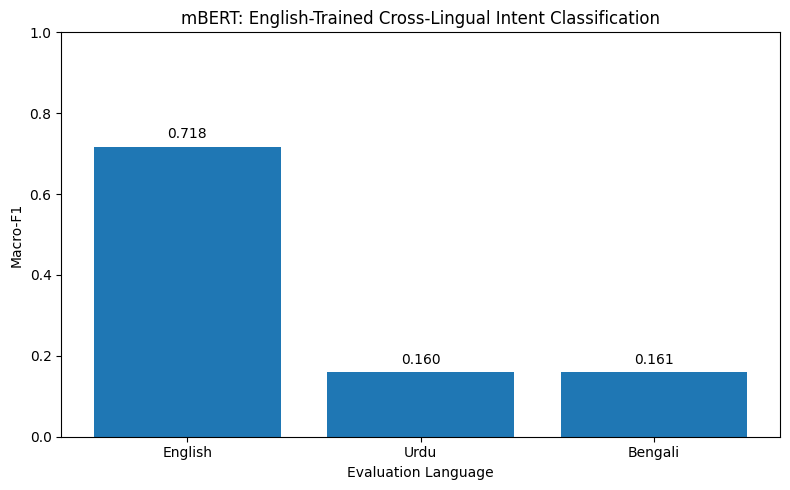

In [30]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

bars = plt.bar(
    results_df["Test Language"],
    results_df["Macro-F1"]
)

plt.ylim(0, 1)
plt.ylabel("Macro-F1")
plt.xlabel("Evaluation Language")
plt.title("mBERT: English-Trained Cross-Lingual Intent Classification")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.02,
        f"{height:.3f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/CrossLingual_AI/"
    "mbert_zero_shot_comparison.png",
    dpi=300
)

plt.show()


## Experiment 2 — XLM-RoBERTa

In [1]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Check Colab runtime settings.")


PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 4.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 61.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 40.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 86.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 76.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 75.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 11.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
c

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

...

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.615024,1.760415,3,0.569267,0.425972



Evaluating Bengali...


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.615024,1.698711,3,0.589106,0.457867



FINAL ZERO-SHOT EVALUATION RESULTS


,Model,Training,Test Language,Accuracy,Macro-F1,F1 Gap vs English
0,XLM-RoBERTa,English only,English,0.8477,0.7218,0.0000
1,XLM-RoBERTa,English only,Urdu,0.5693,0.4260,0.2959
2,XLM-RoBERTa,English only,Bengali,0.5891,0.4579,0.2640


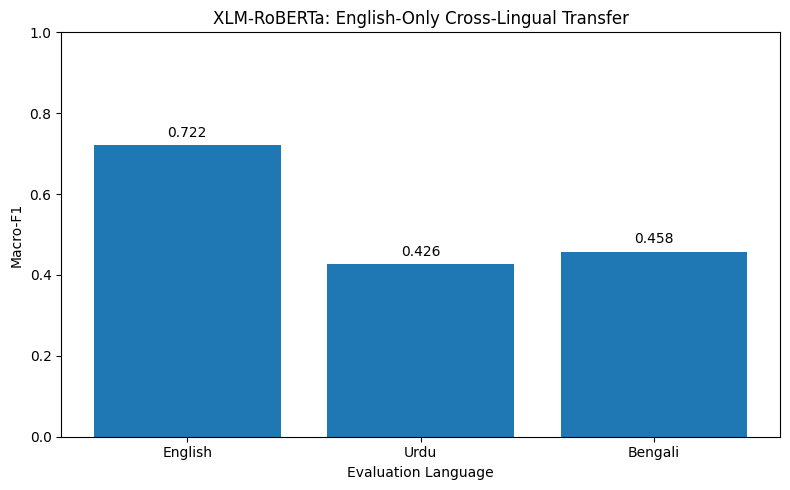


MODEL COMPARISON


,Model,Test Language,Accuracy,Macro-F1
0,mBERT,English,0.8376,0.7176
1,mBERT,Urdu,0.2629,0.1602
2,mBERT,Bengali,0.2572,0.1606
3,XLM-RoBERTa,English,0.8477,0.7218
4,XLM-RoBERTa,Urdu,0.5693,0.4260
5,XLM-RoBERTa,Bengali,0.5891,0.4579


Comparison saved: /content/drive/MyDrive/CrossLingual_AI/mbert_vs_xlmr_comparison.csv

EXPERIMENT 2 COMPLETED
Model: xlm-roberta-base
Training language: English
Evaluation languages: English, Urdu, Bengali
Random seed: 42

Saved artifacts:
Model: /content/drive/MyDrive/CrossLingual_AI/xlmr_final_model
Results: /content/drive/MyDrive/CrossLingual_AI/xlmr_zero_shot_results.csv
Figure: /content/drive/MyDrive/CrossLingual_AI/xlmr_zero_shot_f1.png

All done!


In [2]:

# ============================================================
# CROSS-LINGUAL CONVERSATIONAL AI EVALUATION
# EXPERIMENT 2: XLM-RoBERTa Zero-Shot Transfer
#
# Train: English
# Test: English, Urdu, Bengali
# Dataset: Amazon MASSIVE 1.0
# Model: xlm-roberta-base
# Hardware: Google Colab T4 GPU
# ============================================================

# ------------------------------------------------------------
# STEP 1: Install required libraries
# ------------------------------------------------------------
%pip -q install -U transformers datasets accelerate scikit-learn pandas matplotlib safetensors sentencepiece

# ------------------------------------------------------------
# STEP 2: Import libraries
# ------------------------------------------------------------
import os
import json
import random
import tarfile
import shutil
import requests
import inspect

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers

from google.colab import drive
from datasets import Dataset, DatasetDict
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

# ------------------------------------------------------------
# STEP 3: Set random seed for reproducibility
# ------------------------------------------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# STEP 4: Verify GPU
# ------------------------------------------------------------
print("=" * 60)
print("ENVIRONMENT")
print("=" * 60)

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU unavailable. Enable T4 GPU in Colab."
    )

print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# STEP 5: Mount Google Drive
# ------------------------------------------------------------
drive.mount("/content/drive")

BASE_DIR = "/content/drive/MyDrive/CrossLingual_AI"
os.makedirs(BASE_DIR, exist_ok=True)

# Keep intermediate checkpoints on local Colab storage.
# Save the final model and results to Google Drive.
OUTPUT_DIR = "/content/xlmr_training"
FINAL_MODEL_DIR = os.path.join(BASE_DIR, "xlmr_final_model")

# ------------------------------------------------------------
# STEP 6: Download MASSIVE dataset
# ------------------------------------------------------------
DATA_URL = (
    "https://amazon-massive-nlu-dataset.s3.amazonaws.com/"
    "amazon-massive-dataset-1.0.tar.gz"
)

ARCHIVE = "/content/massive.tar.gz"

if not os.path.exists(ARCHIVE):
    print("\nDownloading MASSIVE dataset...")

    with requests.get(
        DATA_URL,
        stream=True,
        timeout=120
    ) as response:

        response.raise_for_status()

        with open(ARCHIVE, "wb") as file:
            for chunk in response.iter_content(
                chunk_size=1024 * 1024
            ):
                if chunk:
                    file.write(chunk)

DATA_ROOT = "/content/1.0/data"

if not os.path.exists(DATA_ROOT):
    print("Extracting dataset...")

    with tarfile.open(ARCHIVE, "r:gz") as tar:
        tar.extractall(
            path="/content",
            filter="data"
        )

# ------------------------------------------------------------
# STEP 7: Load English, Urdu and Bengali
# ------------------------------------------------------------
LANGUAGES = {
    "English": "en-US",
    "Urdu": "ur-PK",
    "Bengali": "bn-BD"
}

datasets_by_language = {}

for language, code in LANGUAGES.items():

    path = f"{DATA_ROOT}/{code}.jsonl"

    with open(path, "r", encoding="utf-8") as file:
        records = [
            json.loads(line)
            for line in file
        ]

    splits = {}

    for split in ["train", "dev", "test"]:

        selected = [
            {
                "utt": row["utt"],
                "intent": row["intent"],
                "id": row["id"]
            }
            for row in records
            if row["partition"] == split
        ]

        split_name = (
            "validation" if split == "dev" else split
        )

        splits[split_name] = Dataset.from_list(selected)

    datasets_by_language[language] = DatasetDict(splits)

    print(
        f"{language}:",
        {k: len(v) for k, v in splits.items()}
    )

# ------------------------------------------------------------
# STEP 8: Verify consistent intent labels and alignment
# ------------------------------------------------------------
intent_sets = {
    language: set(dataset["train"]["intent"])
    for language, dataset in datasets_by_language.items()
}

assert (
    intent_sets["English"]
    == intent_sets["Urdu"]
    == intent_sets["Bengali"]
), "Intent labels differ between languages."

for split in ["train", "validation", "test"]:

    english_map = {
        row["id"]: row["intent"]
        for row in datasets_by_language["English"][split]
    }

    for language in ["Urdu", "Bengali"]:

        target_map = {
            row["id"]: row["intent"]
            for row in datasets_by_language[language][split]
        }

        assert english_map == target_map, (
            f"Alignment mismatch in {language}/{split}"
        )

print("\nIntent labels and multilingual alignment verified.")

# ------------------------------------------------------------
# STEP 9: Create numeric intent labels
# ------------------------------------------------------------
intent_names = sorted(intent_sets["English"])

label2id = {
    label: idx
    for idx, label in enumerate(intent_names)
}

id2label = {
    idx: label
    for label, idx in label2id.items()
}

num_labels = len(intent_names)

print("Number of intent classes:", num_labels)

# ------------------------------------------------------------
# STEP 10: Load XLM-RoBERTa tokenizer
# ------------------------------------------------------------
MODEL_NAME = "xlm-roberta-base"
MAX_LENGTH = 64

print("\nLoading XLM-RoBERTa tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# ------------------------------------------------------------
# STEP 11: Tokenize all three languages
# ------------------------------------------------------------
def preprocess(examples):

    encoded = tokenizer(
        examples["utt"],
        truncation=True,
        max_length=MAX_LENGTH
    )

    encoded["labels"] = [
        label2id[intent]
        for intent in examples["intent"]
    ]

    return encoded


tokenized_datasets = {}

for language, dataset in datasets_by_language.items():

    tokenized_datasets[language] = dataset.map(
        preprocess,
        batched=True,
        remove_columns=dataset["train"].column_names
    )

    print(f"{language} tokenization completed.")

# ------------------------------------------------------------
# STEP 12: Load pretrained XLM-RoBERTa classifier
# ------------------------------------------------------------
print("\nLoading XLM-RoBERTa model...")

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id
)

print(
    "Model parameters:",
    f"{sum(p.numel() for p in model.parameters()):,}"
)

# ------------------------------------------------------------
# STEP 13: Define evaluation metrics
# ------------------------------------------------------------
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(
        logits,
        axis=-1
    )

    return {
        "accuracy": accuracy_score(
            labels,
            predictions
        ),
        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    }

# ------------------------------------------------------------
# STEP 14: Configure training
# ------------------------------------------------------------
# Use the same core hyperparameters as the mBERT baseline.
# Gradient accumulation is not used, preserving batch size 16.
#
# Warmup: approximately 10% of 2160 training steps.

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,

    num_train_epochs=3,
    learning_rate=2e-5,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,

    weight_decay=0.01,
    warmup_steps=216,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    fp16=True,

    logging_steps=100,
    save_total_limit=1,

    seed=SEED,
    data_seed=SEED,

    dataloader_pin_memory=True,
    report_to="none"
)

# ------------------------------------------------------------
# STEP 15: Initialize Trainer
# ------------------------------------------------------------
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

trainer = Trainer(
    model=model,
    args=training_args,

    train_dataset=tokenized_datasets["English"]["train"],
    eval_dataset=tokenized_datasets["English"]["validation"],

    processing_class=tokenizer,
    data_collator=data_collator,

    compute_metrics=compute_metrics
)

# ------------------------------------------------------------
# STEP 16: Fine-tune XLM-RoBERTa on English
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("TRAINING XLM-RoBERTa ON ENGLISH")
print("=" * 60)

train_result = trainer.train()

print("\nTraining completed.")
print(train_result.metrics)

print(
    "Best checkpoint:",
    trainer.state.best_model_checkpoint
)

print(
    "Best validation macro-F1:",
    trainer.state.best_metric
)

# ------------------------------------------------------------
# STEP 17: Save selected model and tokenizer
# ------------------------------------------------------------
# Save after training so we preserve the best validation model.

os.makedirs(FINAL_MODEL_DIR, exist_ok=True)

trainer.save_model(FINAL_MODEL_DIR)
tokenizer.save_pretrained(FINAL_MODEL_DIR)

print("\nFinal model saved to:", FINAL_MODEL_DIR)

# ------------------------------------------------------------
# STEP 18: Evaluate on held-out test sets
# ------------------------------------------------------------
# Urdu and Bengali are never used for fine-tuning.
# These are zero-shot cross-lingual transfer evaluations.

results = []

for language in ["English", "Urdu", "Bengali"]:

    print(f"\nEvaluating {language}...")

    metrics = trainer.evaluate(
        eval_dataset=tokenized_datasets[language]["test"]
    )

    results.append({
        "Model": "XLM-RoBERTa",
        "Training": "English only",
        "Test Language": language,
        "Accuracy": metrics["eval_accuracy"],
        "Macro-F1": metrics["eval_macro_f1"]
    })

results_df = pd.DataFrame(results)

# ------------------------------------------------------------
# STEP 19: Calculate cross-lingual performance gaps
# ------------------------------------------------------------
english_f1 = results_df.loc[
    results_df["Test Language"] == "English",
    "Macro-F1"
].iloc[0]

results_df["F1 Gap vs English"] = (
    english_f1 - results_df["Macro-F1"]
)

print("\n" + "=" * 60)
print("FINAL ZERO-SHOT EVALUATION RESULTS")
print("=" * 60)

display(results_df.round(4))

# ------------------------------------------------------------
# STEP 20: Save results as CSV
# ------------------------------------------------------------
RESULTS_PATH = os.path.join(
    BASE_DIR,
    "xlmr_zero_shot_results.csv"
)

results_df.to_csv(
    RESULTS_PATH,
    index=False
)

# ------------------------------------------------------------
# STEP 21: Generate research figure
# ------------------------------------------------------------
plt.figure(figsize=(8, 5))

bars = plt.bar(
    results_df["Test Language"],
    results_df["Macro-F1"]
)

plt.ylim(0, 1)
plt.xlabel("Evaluation Language")
plt.ylabel("Macro-F1")
plt.title(
    "XLM-RoBERTa: English-Only Cross-Lingual Transfer"
)

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.02,
        f"{height:.3f}",
        ha="center"
    )

plt.tight_layout()

FIGURE_PATH = os.path.join(
    BASE_DIR,
    "xlmr_zero_shot_f1.png"
)

plt.savefig(
    FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# STEP 22: Compare XLM-RoBERTa with existing mBERT results
# ------------------------------------------------------------
MBERT_PATH = os.path.join(
    BASE_DIR,
    "mbert_zero_shot_results.csv"
)

if os.path.exists(MBERT_PATH):

    mbert_results = pd.read_csv(MBERT_PATH)

    comparison = pd.concat(
        [mbert_results, results_df],
        ignore_index=True
    )

    comparison_path = os.path.join(
        BASE_DIR,
        "mbert_vs_xlmr_comparison.csv"
    )

    comparison.to_csv(
        comparison_path,
        index=False
    )

    print("\nMODEL COMPARISON")
    display(
        comparison[
            ["Model", "Test Language", "Accuracy", "Macro-F1"]
        ].round(4)
    )

    print("Comparison saved:", comparison_path)

else:
    print(
        "\nmBERT results file not found. "
        "XLM-RoBERTa results were saved independently."
    )

# ------------------------------------------------------------
# STEP 23: Final summary
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("EXPERIMENT 2 COMPLETED")
print("=" * 60)

print("Model:", MODEL_NAME)
print("Training language: English")
print("Evaluation languages: English, Urdu, Bengali")
print("Random seed:", SEED)

print("\nSaved artifacts:")
print("Model:", FINAL_MODEL_DIR)
print("Results:", RESULTS_PATH)
print("Figure:", FIGURE_PATH)

print("\nAll done!")


## Experiment 3 — Intent-Level Error Analysis

Device: cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
English test examples: 2974
Urdu test examples: 2974
Bengali test examples: 2974
Intent classes: 60

Evaluating: mBERT


Loading weights:   0%|          | 0/201 [00:05<?, ?it/s]

Processing: English
Processing: Urdu
Processing: Bengali

Evaluating: XLM-RoBERTa


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Processing: English
Processing: Urdu
Processing: Bengali

OVERALL PERFORMANCE


...

,Intent,F1,Precision,Recall,Support
181,alarm_remove,0.0,0.0,0.0,21
182,alarm_set,0.0,0.0,0.0,41
183,audio_volume_down,0.0,0.0,0.0,11
184,audio_volume_mute,0.0,0.0,0.0,32
185,audio_volume_other,0.0,0.0,0.0,6
194,email_addcontact,0.0,0.0,0.0,12
190,cooking_query,0.0,0.0,0.0,0
188,calendar_remove,0.0,0.0,0.0,67
192,datetime_convert,0.0,0.0,0.0,15
205,iot_hue_lightoff,0.0,0.0,0.0,43



10 HARDEST INTENTS: XLM-RoBERTa / Urdu


,Intent,F1,Precision,Recall,Support
120,alarm_query,0.0,0.0,0.0,34
121,alarm_remove,0.0,0.0,0.0,21
123,audio_volume_down,0.0,0.0,0.0,11
125,audio_volume_other,0.0,0.0,0.0,6
132,datetime_convert,0.0,0.0,0.0,15
130,cooking_query,0.0,0.0,0.0,0
147,iot_hue_lightup,0.0,0.0,0.0,27
138,general_greet,0.0,0.0,0.0,1
144,iot_hue_lightdim,0.0,0.0,0.0,21
146,iot_hue_lighton,0.0,0.0,0.0,3



10 HARDEST INTENTS: XLM-RoBERTa / Bengali


,Intent,F1,Precision,Recall,Support
3,audio_volume_down,0.0,0.0,0.0,11
5,audio_volume_other,0.0,0.0,0.0,6
12,datetime_convert,0.0,0.0,0.0,15
10,cooking_query,0.0,0.0,0.0,0
24,iot_hue_lightdim,0.0,0.0,0.0,21
26,iot_hue_lighton,0.0,0.0,0.0,3
27,iot_hue_lightup,0.0,0.0,0.0,27
18,general_greet,0.0,0.0,0.0,1
36,music_settings,0.0,0.0,0.0,6
33,music_dislikeness,0.0,0.0,0.0,4


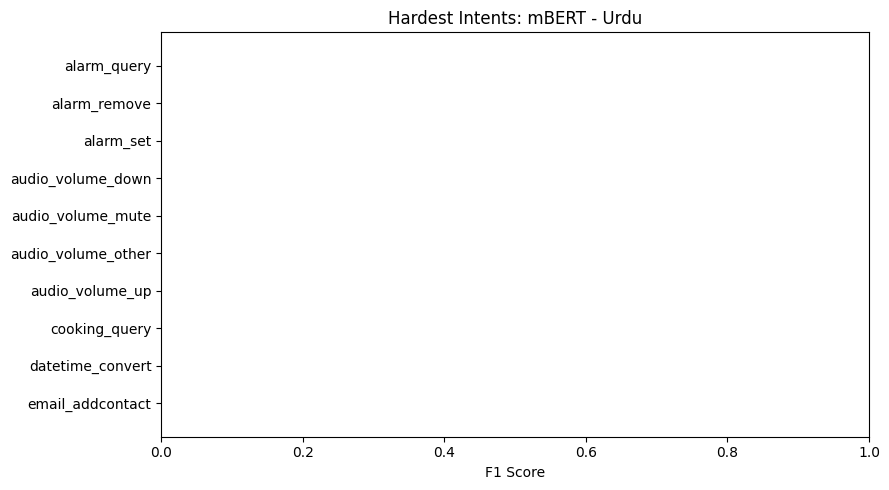

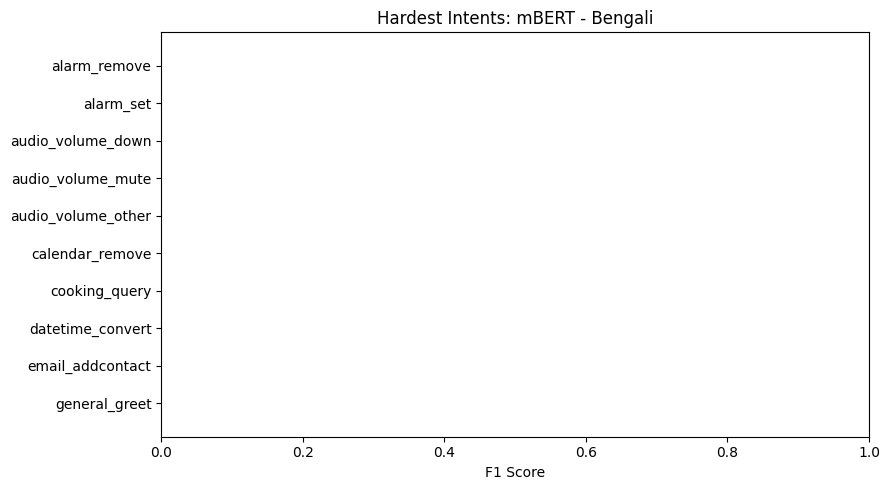

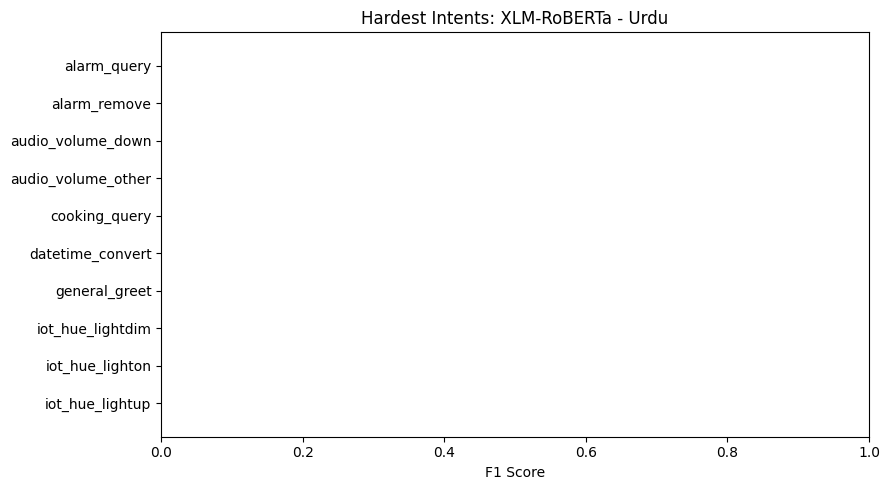

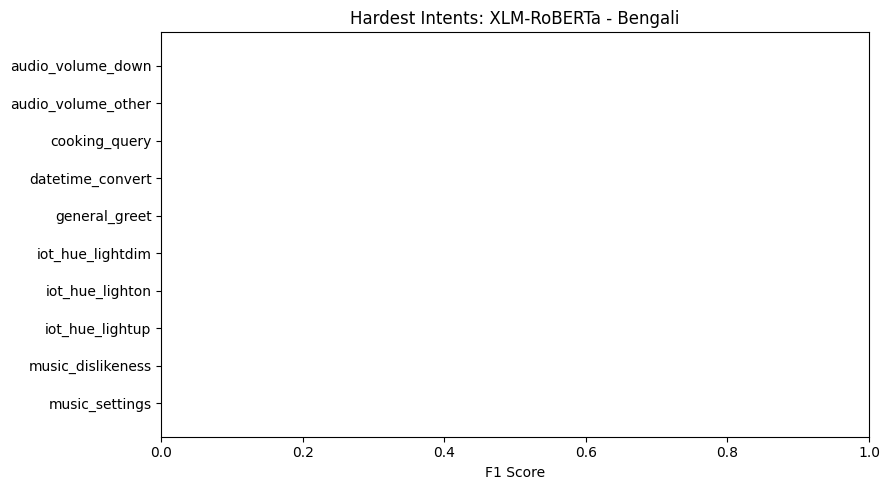

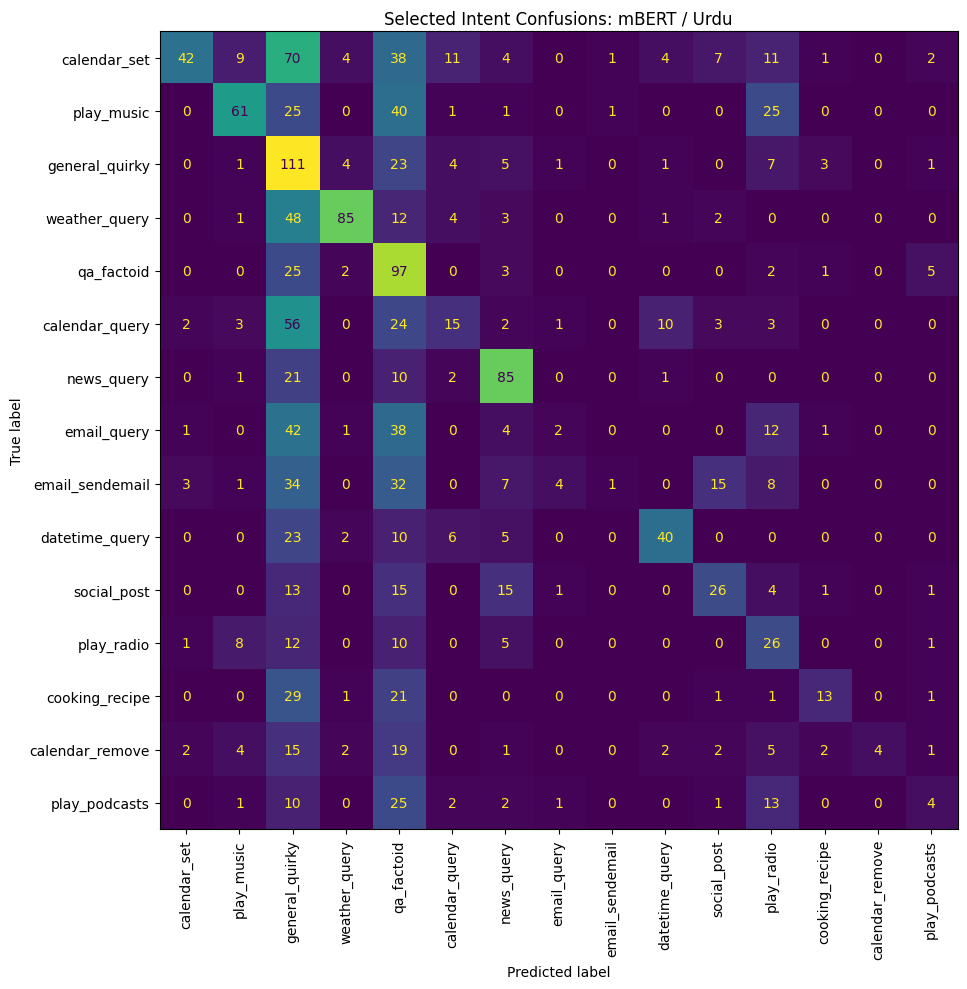

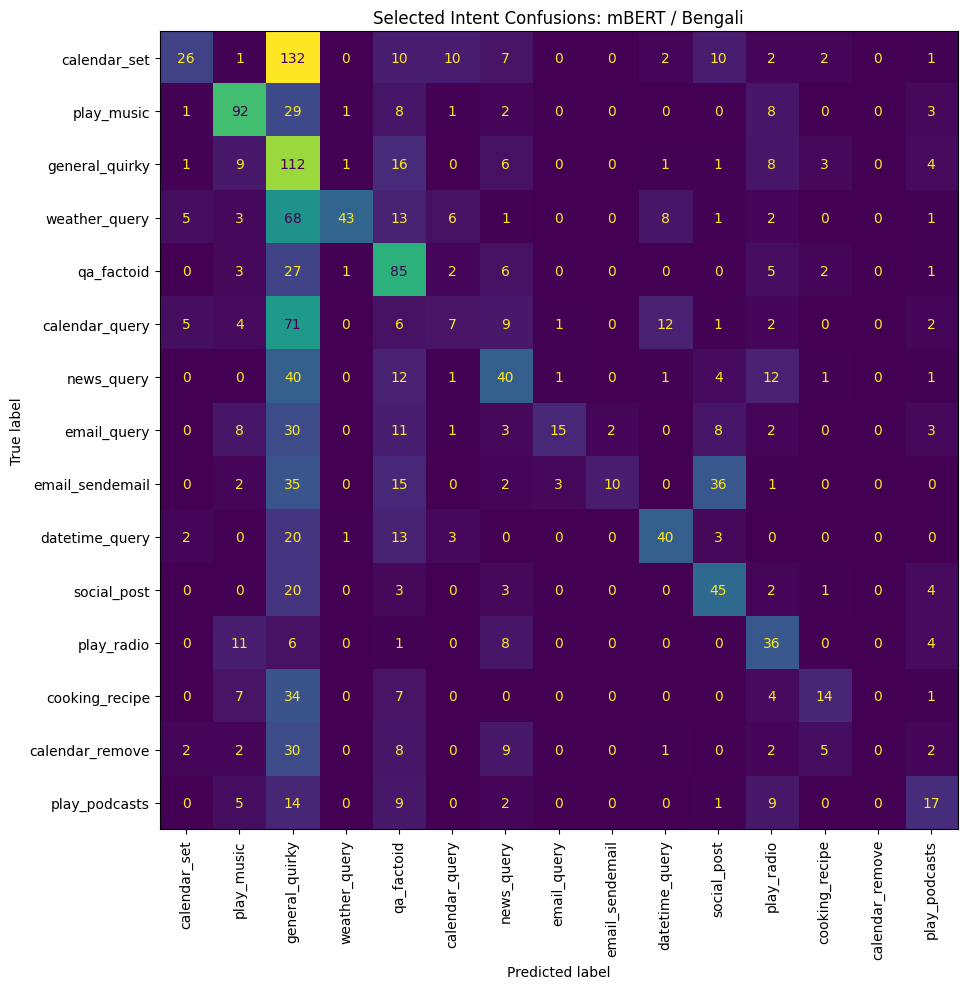

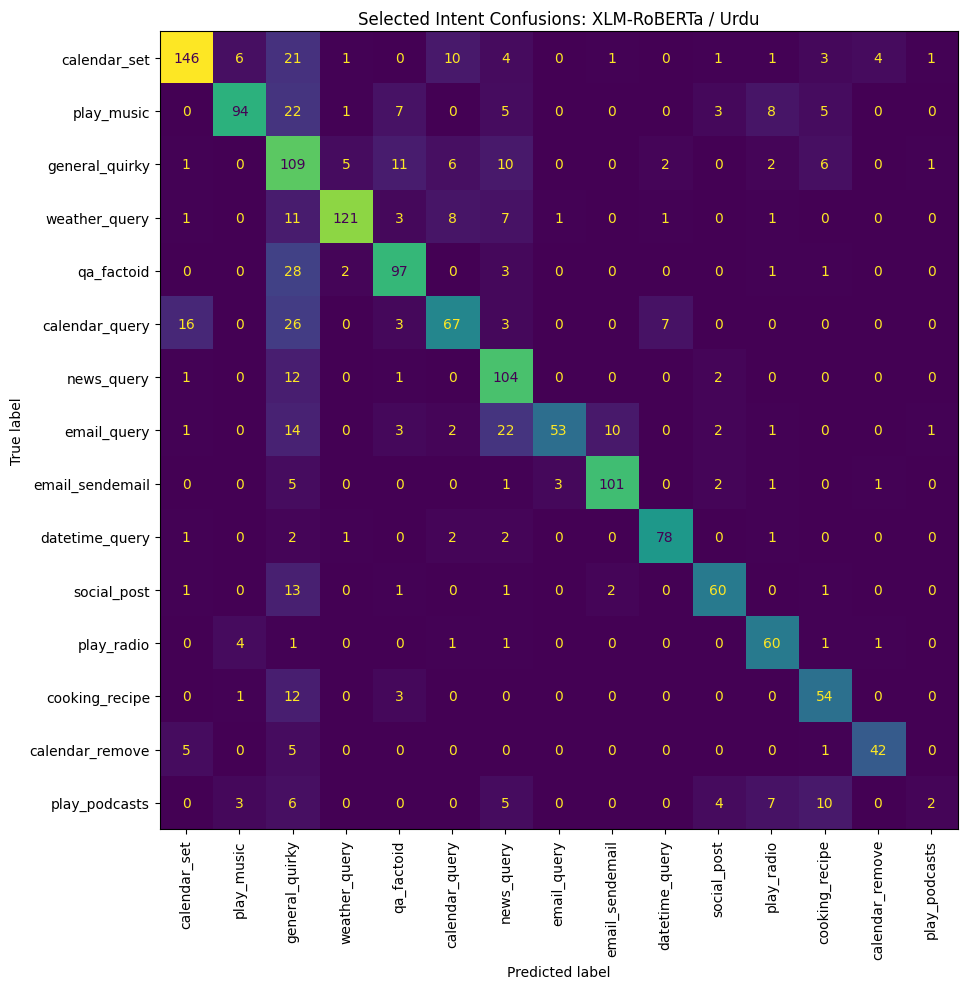

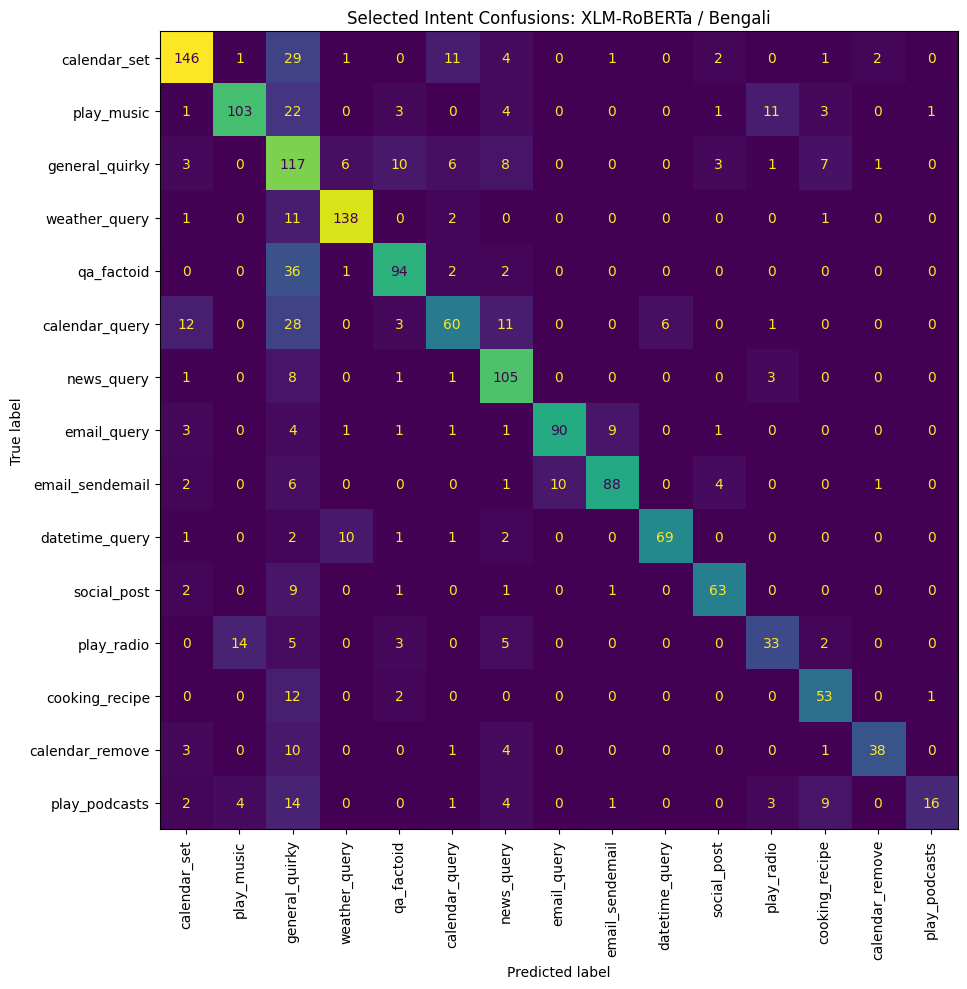


EXAMPLE ERRORS

mBERT / Urdu


,Text,True Intent,Predicted Intent
2974,مجھے اس ہفتے صبح کے پانچ بجے جگا دیں,alarm_set,calendar_set
2975,خاموش,audio_volume_mute,general_quirky
2976,ہمیں صرف گلابی کی ضرورت ہے,iot_hue_lightchange,general_quirky
2977,اور اندھیرا چھا گیا ہے,iot_hue_lighton,general_quirky
2978,ماہی سونے کے باتھ روم کی روشنی بند کرو,iot_hue_lightoff,play_music
2979,شار,iot_cleaning,qa_factoid
2980,دالان ہوور,iot_cleaning,play_radio
2982,اولے کیا ہو رہا ہے,general_greet,general_quirky
2984,علی بتائو مبھے وفت جی. ایم. ٹی. پلس پانچ کا,datetime_convert,play_radio
2985,میرا صبح سات بجے کا الارم منسوخ کر دو,alarm_remove,play_radio



mBERT / Bengali


,Text,True Intent,Predicted Intent
5948,এই সপ্তাহে পাঁচটায় আমাকে ঘুম থেকে জাগাও,alarm_set,calendar_set
5949,শান্ত,audio_volume_mute,general_quirky
5950,গোলাপী আমাদের প্রয়োজন সব,iot_hue_lightchange,play_music
5951,এবং অন্ধকার কমে গেছে,iot_hue_lighton,general_quirky
5952,বেডরুমের আলো নিভিয়ে দাও,iot_hue_lightoff,news_query
5953,এখানে নোংরা কিছু শোরগোল করো,iot_cleaning,cooking_recipe
5954,বারান্দা ঝাঁটান,iot_cleaning,play_radio
5956,অলি কি খবর,general_greet,news_query
5958,olly আমাকে g. m. t. plus five সময় বলুন,datetime_convert,qa_maths
5959,আমার সাত সকালে অ্যালার্ম বাতিল করুন,alarm_remove,general_quirky



XLM-RoBERTa / Urdu


,Text,True Intent,Predicted Intent
11898,ہمیں صرف گلابی کی ضرورت ہے,iot_hue_lightchange,cooking_recipe
11899,اور اندھیرا چھا گیا ہے,iot_hue_lighton,weather_query
11901,شار,iot_cleaning,general_quirky
11902,دالان ہوور,iot_cleaning,qa_factoid
11904,اولے کیا ہو رہا ہے,general_greet,news_query
11906,علی بتائو مبھے وفت جی. ایم. ٹی. پلس پانچ کا,datetime_convert,news_query
11907,میرا صبح سات بجے کا الارم منسوخ کر دو,alarm_remove,calendar_remove
11908,میں نے کیا الارمز لگا رکھا ہے,alarm_query,general_quirky
11909,مجھے میرے الارم کے بارے میں بتائیں,alarm_query,general_quirky
11910,مجھے سناترا کے گانے پسند ہیں,music_likeness,play_music



XLM-RoBERTa / Bengali


,Text,True Intent,Predicted Intent
14870,এই সপ্তাহে পাঁচটায় আমাকে ঘুম থেকে জাগাও,alarm_set,weather_query
14871,শান্ত,audio_volume_mute,play_music
14872,গোলাপী আমাদের প্রয়োজন সব,iot_hue_lightchange,general_quirky
14873,এবং অন্ধকার কমে গেছে,iot_hue_lighton,weather_query
14875,এখানে নোংরা কিছু শোরগোল করো,iot_cleaning,play_audiobook
14876,বারান্দা ঝাঁটান,iot_cleaning,general_quirky
14878,অলি কি খবর,general_greet,news_query
14880,olly আমাকে g. m. t. plus five সময় বলুন,datetime_convert,datetime_query
14881,আমার সাত সকালে অ্যালার্ম বাতিল করুন,alarm_remove,calendar_remove
14882,আমি কি অ্যালার্ম সেট করেছি,alarm_query,general_quirky



MODEL DISAGREEMENT SUMMARY
English | XLM-R wins: 132 | mBERT wins: 103
Urdu | XLM-R wins: 1034 | mBERT wins: 122
Bengali | XLM-R wins: 1122 | mBERT wins: 139

EXPERIMENT 3 COMPLETED
All files saved to:
/content/drive/MyDrive/CrossLingual_AI/error_analysis


In [3]:

# ============================================================
# EXPERIMENT 3: CROSS-LINGUAL INTENT ERROR ANALYSIS
# Models: mBERT and XLM-RoBERTa
# Languages: English, Urdu, Bengali
# Dataset: Amazon MASSIVE 1.0
# No model training required
# ============================================================

import os
import json
import tarfile
import requests
import random
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from google.colab import drive
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding
)
from datasets import Dataset
from torch.utils.data import DataLoader
from sklearn.metrics import (
    precision_recall_fscore_support,
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# STEP 1: Reproducibility and device
# ------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# ------------------------------------------------------------
# STEP 2: Mount Google Drive and locate saved models
# ------------------------------------------------------------
drive.mount("/content/drive")

BASE_DIR = "/content/drive/MyDrive/CrossLingual_AI"
RESULTS_DIR = os.path.join(BASE_DIR, "error_analysis")

os.makedirs(RESULTS_DIR, exist_ok=True)

MODEL_PATHS = {
    "mBERT": os.path.join(
        BASE_DIR, "mbert_checkpoint_fixed"
    ),
    "XLM-RoBERTa": os.path.join(
        BASE_DIR, "xlmr_final_model"
    )
}

for name, path in MODEL_PATHS.items():
    if not os.path.exists(
        os.path.join(path, "model.safetensors")
    ):
        raise FileNotFoundError(
            f"Missing model file for {name}: {path}"
        )

# ------------------------------------------------------------
# STEP 3: Load original MASSIVE 1.0 dataset
# ------------------------------------------------------------
DATA_URL = (
    "https://amazon-massive-nlu-dataset.s3.amazonaws.com/"
    "amazon-massive-dataset-1.0.tar.gz"
)

ARCHIVE = "/content/massive.tar.gz"
DATA_ROOT = "/content/1.0/data"

if not os.path.exists(DATA_ROOT):

    if not os.path.exists(ARCHIVE):
        print("Downloading MASSIVE dataset...")

        with requests.get(
            DATA_URL, stream=True, timeout=120
        ) as response:
            response.raise_for_status()

            with open(ARCHIVE, "wb") as file:
                for chunk in response.iter_content(
                    chunk_size=1024 * 1024
                ):
                    if chunk:
                        file.write(chunk)

    print("Extracting MASSIVE dataset...")

    with tarfile.open(ARCHIVE, "r:gz") as tar:
        tar.extractall(
            path="/content",
            filter="data"
        )

LANGUAGES = {
    "English": "en-US",
    "Urdu": "ur-PK",
    "Bengali": "bn-BD"
}

test_data = {}

for language, code in LANGUAGES.items():

    path = f"{DATA_ROOT}/{code}.jsonl"

    with open(path, "r", encoding="utf-8") as file:
        records = [
            json.loads(line)
            for line in file
        ]

    test_records = [
        {
            "id": row["id"],
            "utt": row["utt"],
            "intent": row["intent"]
        }
        for row in records
        if row["partition"] == "test"
    ]

    test_data[language] = test_records

    print(language, "test examples:", len(test_records))

# ------------------------------------------------------------
# STEP 4: Create a shared label mapping
# ------------------------------------------------------------
# Use the label mapping saved with the trained models.
# This avoids accidentally changing class IDs.

with open(
    os.path.join(
        MODEL_PATHS["mBERT"], "config.json"
    ),
    encoding="utf-8"
) as file:
    config = json.load(file)

id2label = {
    int(k): v
    for k, v in config["id2label"].items()
}

label2id = {
    v: k for k, v in id2label.items()
}

num_labels = len(id2label)

print("Intent classes:", num_labels)

# ------------------------------------------------------------
# STEP 5: Prediction function
# ------------------------------------------------------------
# Run batched inference on the GPU.
# No gradients are needed during evaluation.

def predict_model(model, tokenizer, records):

    texts = [row["utt"] for row in records]

    encoded = tokenizer(
        texts,
        truncation=True,
        max_length=64,
        padding=False
    )

    dataset = Dataset.from_dict(encoded)

    collator = DataCollatorWithPadding(
        tokenizer=tokenizer,
        return_tensors="pt"
    )

    loader = DataLoader(
        dataset,
        batch_size=32,
        shuffle=False,
        collate_fn=collator
    )

    predictions = []

    model.eval()

    with torch.inference_mode():

        for batch in loader:

            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            outputs = model(**batch)

            predicted = outputs.logits.argmax(
                dim=-1
            )

            predictions.extend(
                predicted.cpu().tolist()
            )

    return predictions

# ------------------------------------------------------------
# STEP 6: Evaluate both models
# ------------------------------------------------------------
all_predictions = []
all_metrics = []

for model_name, model_path in MODEL_PATHS.items():

    print("\n" + "=" * 55)
    print("Evaluating:", model_name)
    print("=" * 55)

    tokenizer = AutoTokenizer.from_pretrained(
        model_path
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_path
    ).to(device)

    # Verify the saved class mapping.
    assert model.config.id2label == id2label, (
        f"Label mapping mismatch for {model_name}"
    )

    for language, records in test_data.items():

        print("Processing:", language)

        y_true = [
            label2id[row["intent"]]
            for row in records
        ]

        y_pred = predict_model(
            model, tokenizer, records
        )

        # Overall metrics
        accuracy = accuracy_score(
            y_true, y_pred
        )

        macro_f1 = f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )

        all_metrics.append({
            "Model": model_name,
            "Language": language,
            "Accuracy": accuracy,
            "Macro-F1": macro_f1
        })

        # Store every prediction for error analysis.
        for row, true_id, pred_id in zip(
            records, y_true, y_pred
        ):

            all_predictions.append({
                "Model": model_name,
                "Language": language,
                "ID": row["id"],
                "Text": row["utt"],
                "True Intent": id2label[true_id],
                "Predicted Intent": id2label[pred_id],
                "Correct": true_id == pred_id
            })

    # Free GPU memory before loading next model.
    del model
    del tokenizer
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ------------------------------------------------------------
# STEP 7: Save predictions and overall metrics
# ------------------------------------------------------------
predictions_df = pd.DataFrame(all_predictions)
metrics_df = pd.DataFrame(all_metrics)

predictions_df.to_csv(
    os.path.join(
        RESULTS_DIR, "all_predictions.csv"
    ),
    index=False
)

metrics_df.to_csv(
    os.path.join(
        RESULTS_DIR, "overall_metrics.csv"
    ),
    index=False
)

print("\nOVERALL PERFORMANCE")
display(metrics_df.round(4))

# ------------------------------------------------------------
# STEP 8: Calculate per-intent precision, recall and F1
# ------------------------------------------------------------
intent_results = []

for (model_name, language), group in predictions_df.groupby(
    ["Model", "Language"]
):

    y_true = [
        label2id[x]
        for x in group["True Intent"]
    ]

    y_pred = [
        label2id[x]
        for x in group["Predicted Intent"]
    ]

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=list(range(num_labels)),
            zero_division=0
        )
    )

    for intent_id in range(num_labels):

        intent_results.append({
            "Model": model_name,
            "Language": language,
            "Intent": id2label[intent_id],
            "Precision": precision[intent_id],
            "Recall": recall[intent_id],
            "F1": f1[intent_id],
            "Support": support[intent_id]
        })

intent_df = pd.DataFrame(intent_results)

intent_df.to_csv(
    os.path.join(
        RESULTS_DIR, "per_intent_metrics.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# STEP 9: Find the 10 most difficult intents
# ------------------------------------------------------------
for model_name in MODEL_PATHS:

    for language in ["Urdu", "Bengali"]:

        subset = intent_df[
            (intent_df["Model"] == model_name)
            & (intent_df["Language"] == language)
        ]

        hardest = subset.sort_values(
            "F1", ascending=True
        ).head(10)

        print(
            f"\n10 HARDEST INTENTS: {model_name} / {language}"
        )

        display(
            hardest[
                ["Intent", "F1", "Precision", "Recall", "Support"]
            ].round(4)
        )

# ------------------------------------------------------------
# STEP 10: Plot hardest intents
# ------------------------------------------------------------
for model_name in MODEL_PATHS:

    for language in ["Urdu", "Bengali"]:

        subset = intent_df[
            (intent_df["Model"] == model_name)
            & (intent_df["Language"] == language)
        ]

        hardest = subset.nsmallest(10, "F1")

        plt.figure(figsize=(9, 5))

        plt.barh(
            hardest["Intent"],
            hardest["F1"]
        )

        plt.xlabel("F1 Score")
        plt.title(
            f"Hardest Intents: {model_name} - {language}"
        )

        plt.xlim(0, 1)
        plt.gca().invert_yaxis()
        plt.tight_layout()

        filename = (
            f"hardest_{model_name}_{language}.png"
        )

        plt.savefig(
            os.path.join(RESULTS_DIR, filename),
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

# ------------------------------------------------------------
# STEP 11: Generate confusion matrices
# ------------------------------------------------------------
# Full 60x60 matrices are saved as CSV.
# For readability, plot the 15 most frequent true intents.

for model_name in MODEL_PATHS:

    for language in ["Urdu", "Bengali"]:

        subset = predictions_df[
            (predictions_df["Model"] == model_name)
            & (predictions_df["Language"] == language)
        ]

        y_true = [
            label2id[x]
            for x in subset["True Intent"]
        ]

        y_pred = [
            label2id[x]
            for x in subset["Predicted Intent"]
        ]

        cm = confusion_matrix(
            y_true,
            y_pred,
            labels=list(range(num_labels))
        )

        cm_df = pd.DataFrame(
            cm,
            index=[id2label[i] for i in range(num_labels)],
            columns=[id2label[i] for i in range(num_labels)]
        )

        cm_df.to_csv(
            os.path.join(
                RESULTS_DIR,
                f"confusion_{model_name}_{language}.csv"
            )
        )

        # Identify frequent true classes.
        frequent_ids = np.argsort(
            cm.sum(axis=1)
        )[-15:][::-1]

        # Display the selected true/predicted class submatrix.
        selected_cm = cm[
            np.ix_(frequent_ids, frequent_ids)
        ]

        selected_names = [
            id2label[i] for i in frequent_ids
        ]

        fig, ax = plt.subplots(figsize=(12, 10))

        display_cm = ConfusionMatrixDisplay(
            confusion_matrix=selected_cm,
            display_labels=selected_names
        )

        display_cm.plot(
            ax=ax,
            xticks_rotation=90,
            values_format="d",
            colorbar=False
        )

        plt.title(
            f"Selected Intent Confusions: {model_name} / {language}"
        )

        plt.tight_layout()

        plt.savefig(
            os.path.join(
                RESULTS_DIR,
                f"confusion_plot_{model_name}_{language}.png"
            ),
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

# ------------------------------------------------------------
# STEP 12: Export incorrect predictions
# ------------------------------------------------------------
errors_df = predictions_df[
    predictions_df["Correct"] == False
].copy()

errors_df.to_csv(
    os.path.join(
        RESULTS_DIR, "incorrect_predictions.csv"
    ),
    index=False
)

print("\nEXAMPLE ERRORS")

for model_name in MODEL_PATHS:

    for language in ["Urdu", "Bengali"]:

        subset = errors_df[
            (errors_df["Model"] == model_name)
            & (errors_df["Language"] == language)
        ]

        print(f"\n{model_name} / {language}")

        display(
            subset[
                ["Text", "True Intent", "Predicted Intent"]
            ].head(10)
        )

# ------------------------------------------------------------
# STEP 13: Compare model predictions on matched examples
# ------------------------------------------------------------
# Both models evaluated the same MASSIVE example IDs.

mbert_df = predictions_df[
    predictions_df["Model"] == "mBERT"
][
    ["Language", "ID", "Correct", "Predicted Intent"]
].rename(columns={
    "Correct": "mBERT Correct",
    "Predicted Intent": "mBERT Prediction"
})

xlmr_df = predictions_df[
    predictions_df["Model"] == "XLM-RoBERTa"
][
    ["Language", "ID", "Text", "True Intent",
     "Correct", "Predicted Intent"]
].rename(columns={
    "Correct": "XLM-R Correct",
    "Predicted Intent": "XLM-R Prediction"
})

comparison_df = xlmr_df.merge(
    mbert_df,
    on=["Language", "ID"],
    how="inner",
    validate="one_to_one"
)

# Cases where XLM-R is correct and mBERT is wrong.
xlmr_wins = comparison_df[
    (comparison_df["XLM-R Correct"] == True)
    & (comparison_df["mBERT Correct"] == False)
]

xlmr_wins.to_csv(
    os.path.join(
        RESULTS_DIR, "xlmr_correct_mbert_wrong.csv"
    ),
    index=False
)

# Cases where mBERT is correct and XLM-R is wrong.
mbert_wins = comparison_df[
    (comparison_df["mBERT Correct"] == True)
    & (comparison_df["XLM-R Correct"] == False)
]

mbert_wins.to_csv(
    os.path.join(
        RESULTS_DIR, "mbert_correct_xlmr_wrong.csv"
    ),
    index=False
)

print("\nMODEL DISAGREEMENT SUMMARY")

for language in ["English", "Urdu", "Bengali"]:

    print(
        language,
        "| XLM-R wins:",
        len(xlmr_wins[xlmr_wins["Language"] == language]),
        "| mBERT wins:",
        len(mbert_wins[mbert_wins["Language"] == language])
    )

# ------------------------------------------------------------
# STEP 14: Save experiment configuration
# ------------------------------------------------------------
experiment_info = {
    "dataset": "Amazon MASSIVE 1.0",
    "training_language": "English",
    "evaluation_languages": list(LANGUAGES.keys()),
    "models": list(MODEL_PATHS.keys()),
    "max_length": 64,
    "seed": SEED,
    "evaluation_split": "test",
    "num_intents": num_labels
}

with open(
    os.path.join(RESULTS_DIR, "experiment_info.json"),
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        experiment_info,
        file,
        indent=4
    )

print("\n" + "=" * 60)
print("EXPERIMENT 3 COMPLETED")
print("=" * 60)

print("All files saved to:")
print(RESULTS_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded predictions: 17844

VERIFIED METRICS FROM SAVED PREDICTIONS


,Model,Language,Examples,Accuracy,Macro-F1
0,XLM-RoBERTa,Bengali,2974,0.587761,0.448035
1,XLM-RoBERTa,English,2974,0.847344,0.709195
2,XLM-RoBERTa,Urdu,2974,0.569603,0.419016
3,mBERT,Bengali,2974,0.257229,0.157972
4,mBERT,English,2974,0.837592,0.705663
5,mBERT,Urdu,2974,0.262946,0.157546



REFERENCE VS SAVED-PREDICTION COMPARISON


,Model,Language,Accuracy Difference,Macro-F1 Difference
0,XLM-RoBERTa,Bengali,-0.001345,-0.009831
1,XLM-RoBERTa,English,-0.000336,-0.012634
2,XLM-RoBERTa,Urdu,0.000336,-0.006956
3,mBERT,Bengali,0.000000,-0.002677
4,mBERT,English,0.000000,-0.011960
5,mBERT,Urdu,0.000000,-0.002670




HARDEST SUPPORTED INTENTS: XLM-RoBERTa / Bengali


...

,Intent,F1,Precision,Recall,Support
252,datetime_convert,0.0000,0.0000,0.0000,15
243,audio_volume_down,0.0000,0.0000,0.0000,11
245,audio_volume_other,0.0000,0.0000,0.0000,6
276,music_settings,0.0000,0.0000,0.0000,6
273,music_dislikeness,0.0000,0.0000,0.0000,4
266,iot_hue_lighton,0.0000,0.0000,0.0000,3
258,general_greet,0.0000,0.0000,0.0000,1
264,iot_hue_lightdim,0.1538,0.4000,0.0952,21
269,iot_wemo_on,0.1818,1.0000,0.1000,10
246,audio_volume_up,0.5238,0.3793,0.8462,13



HARDEST SUPPORTED INTENTS: mBERT / Urdu


,Intent,F1,Precision,Recall,Support
325,iot_hue_lightoff,0.0,0.0,0.0,43
348,recommendation_events,0.0,0.0,0.0,43
302,alarm_set,0.0,0.0,0.0,41
322,iot_coffee,0.0,0.0,0.0,36
334,music_likeness,0.0,0.0,0.0,36
357,transport_ticket,0.0,0.0,0.0,35
300,alarm_query,0.0,0.0,0.0,34
304,audio_volume_mute,0.0,0.0,0.0,32
327,iot_hue_lightup,0.0,0.0,0.0,27
321,iot_cleaning,0.0,0.0,0.0,26



Loading tokenizer: mBERT
Tokenizing mBERT / Bengali
Tokenizing mBERT / English
Tokenizing mBERT / Urdu

Loading tokenizer: XLM-RoBERTa
Tokenizing XLM-RoBERTa / Bengali
Tokenizing XLM-RoBERTa / English
Tokenizing XLM-RoBERTa / Urdu

TOKENIZATION SUMMARY


,Model,Language,Examples,Average_Tokens,Median_Tokens,Average_Subwords_Per_Word,Truncation_Rate,Accuracy
0,XLM-RoBERTa,Bengali,2974,12.318,11.0,1.745,0.034,58.776
1,XLM-RoBERTa,English,2974,10.030,9.0,1.185,0.034,84.734
2,XLM-RoBERTa,Urdu,2974,11.900,11.0,1.283,0.000,56.960
3,mBERT,Bengali,2974,17.795,16.0,2.684,0.034,25.723
4,mBERT,English,2974,10.459,10.0,1.256,0.034,83.759
5,mBERT,Urdu,2974,15.845,15.0,1.810,0.000,26.295


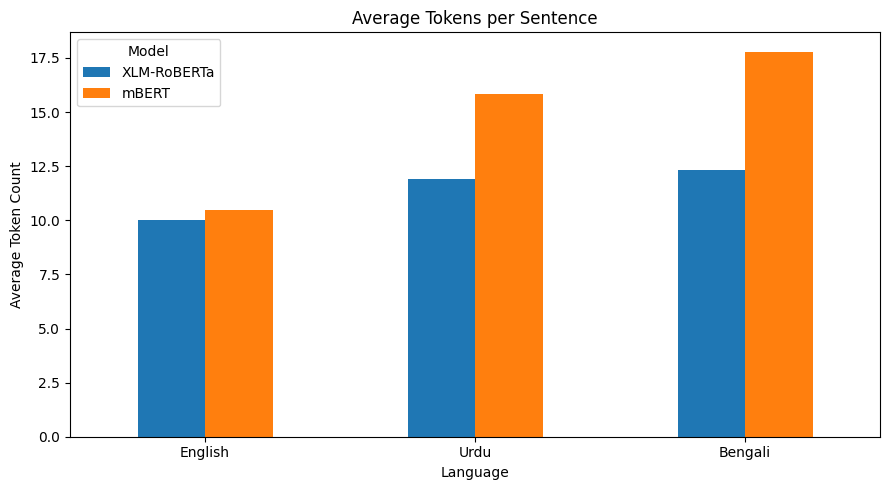


ACCURACY BY TOKEN LENGTH


,Model,Language,Length Group,Examples,Accuracy
0,XLM-RoBERTa,Bengali,1-8,706,64.87
1,XLM-RoBERTa,Bengali,9-16,1738,55.58
2,XLM-RoBERTa,Bengali,17-32,511,61.64
3,XLM-RoBERTa,Bengali,33-64,18,50.00
4,XLM-RoBERTa,Bengali,65+,1,0.00
5,XLM-RoBERTa,English,1-8,1168,80.65
6,XLM-RoBERTa,English,9-16,1622,87.73
7,XLM-RoBERTa,English,17-32,182,85.16
8,XLM-RoBERTa,English,33-64,1,0.00
9,XLM-RoBERTa,English,65+,1,0.00


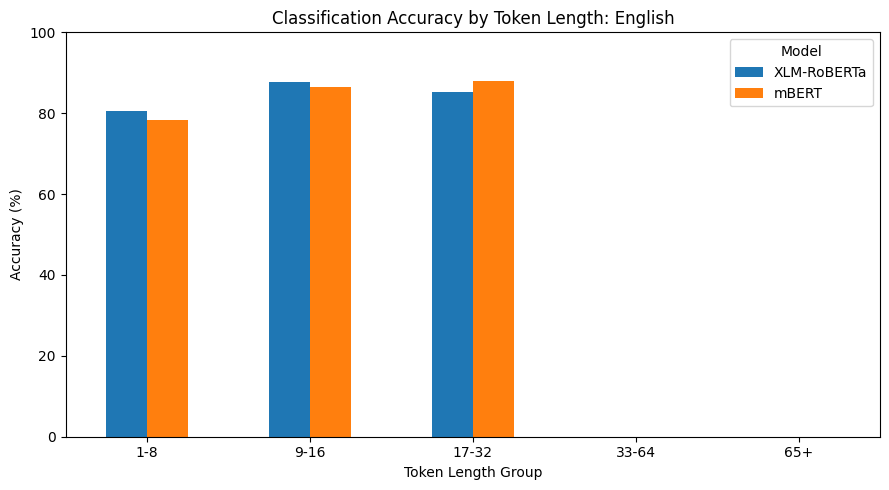

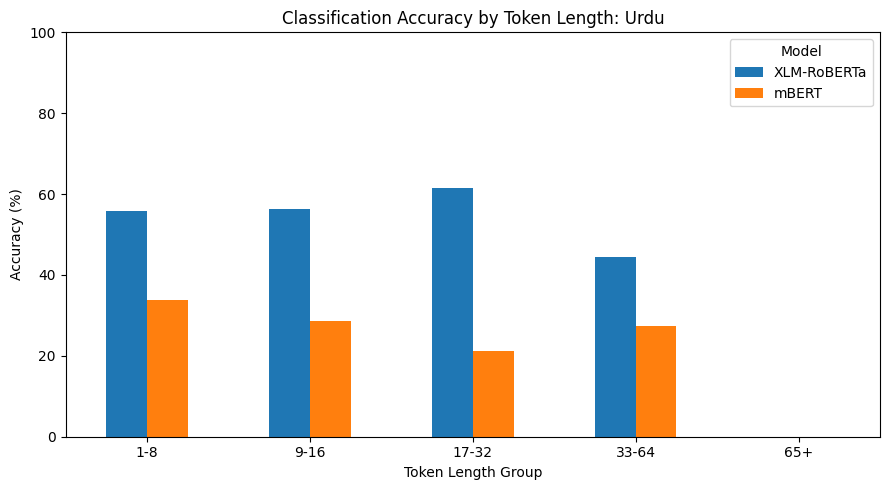

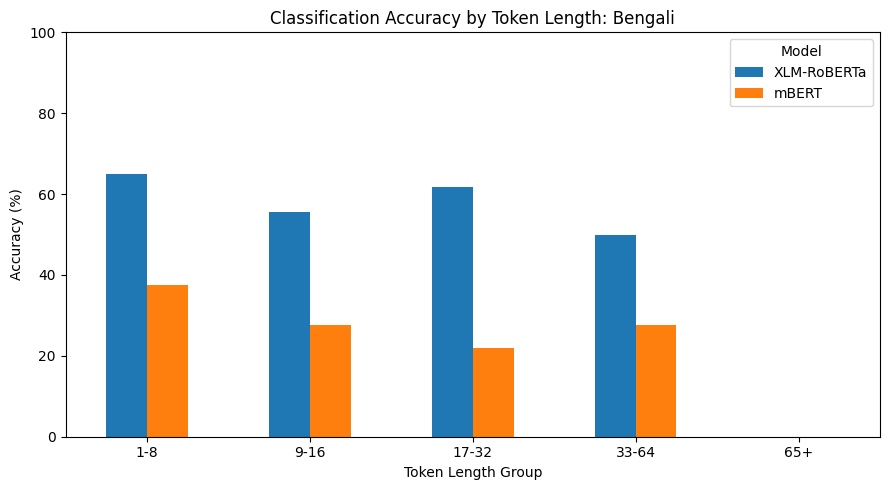


EXPERIMENT 4 COMPLETED
Verification completed.
Zero-support intents excluded from hardest rankings.
Tokenization analyzed for both models.
All results saved to: /content/drive/MyDrive/CrossLingual_AI/tokenization_analysis


In [4]:

# ==============================================================
# EXPERIMENT 4: EVALUATION VERIFICATION + TOKENIZATION ANALYSIS
# Cross-Lingual Conversational AI Evaluation
#
# Models: mBERT and XLM-RoBERTa
# Languages: English, Urdu, Bengali
#
# No retraining. Uses saved predictions and tokenizers.
# ==============================================================

import os
import json
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
from transformers import AutoTokenizer
from sklearn.metrics import accuracy_score, f1_score

# --------------------------------------------------------------
# STEP 1: Mount Google Drive and define paths
# --------------------------------------------------------------

drive.mount("/content/drive")

BASE_DIR = "/content/drive/MyDrive/CrossLingual_AI"
ERROR_DIR = os.path.join(BASE_DIR, "error_analysis")
OUTPUT_DIR = os.path.join(BASE_DIR, "tokenization_analysis")

os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_PATHS = {
    "mBERT": os.path.join(BASE_DIR, "mbert_checkpoint_fixed"),
    "XLM-RoBERTa": os.path.join(BASE_DIR, "xlmr_final_model")
}

PREDICTIONS_PATH = os.path.join(
    ERROR_DIR, "all_predictions.csv"
)

INTENT_PATH = os.path.join(
    ERROR_DIR, "per_intent_metrics.csv"
)

# Check that the required files exist.
for path in [PREDICTIONS_PATH, INTENT_PATH]:
    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Required file not found: {path}"
        )

# --------------------------------------------------------------
# STEP 2: Load existing prediction and intent-level results
# --------------------------------------------------------------

predictions_df = pd.read_csv(PREDICTIONS_PATH)
intent_df = pd.read_csv(INTENT_PATH)

# Preserve example IDs as strings for reliable matching.
predictions_df["ID"] = predictions_df["ID"].astype(str)

# Check for missing or duplicate records.
required_columns = [
    "Model", "Language", "ID", "Text",
    "True Intent", "Predicted Intent", "Correct"
]

assert all(
    col in predictions_df.columns
    for col in required_columns
), "Missing required columns in predictions file."

assert not predictions_df.duplicated(
    ["Model", "Language", "ID"]
).any(), "Duplicate model/language/example IDs detected."

print("Loaded predictions:", len(predictions_df))

# --------------------------------------------------------------
# STEP 3: Recalculate accuracy and macro-F1
# --------------------------------------------------------------
# This checks whether the saved predictions reproduce
# the Experiment 3 metrics.

verification_rows = []

for (model_name, language), group in predictions_df.groupby(
    ["Model", "Language"]
):

    accuracy = accuracy_score(
        group["True Intent"],
        group["Predicted Intent"]
    )

    # Match the original experiment's 60-label macro-F1
    # calculation, including labels absent from the test set.
    label_names = sorted(
        set(
            intent_df[
                (intent_df["Model"] == model_name)
                & (intent_df["Language"] == language)
            ]["Intent"]
        )
    )

    macro_f1 = f1_score(
        group["True Intent"],
        group["Predicted Intent"],
        labels=label_names,
        average="macro",
        zero_division=0
    )

    verification_rows.append({
        "Model": model_name,
        "Language": language,
        "Examples": len(group),
        "Accuracy": accuracy,
        "Macro-F1": macro_f1
    })

verification_df = pd.DataFrame(verification_rows)

print("\nVERIFIED METRICS FROM SAVED PREDICTIONS")
display(verification_df.round(6))

verification_df.to_csv(
    os.path.join(OUTPUT_DIR, "verified_metrics.csv"),
    index=False
)

# --------------------------------------------------------------
# STEP 4: Compare against previously saved benchmark results
# --------------------------------------------------------------

reference_files = {
    "mBERT": os.path.join(
        BASE_DIR, "mbert_zero_shot_results.csv"
    ),
    "XLM-RoBERTa": os.path.join(
        BASE_DIR, "xlmr_zero_shot_results.csv"
    )
}

reference_rows = []

for model_name, path in reference_files.items():

    if not os.path.isfile(path):
        print(f"Reference file unavailable: {path}")
        continue

    reference = pd.read_csv(path)

    # Handle expected language column name.
    language_column = (
        "Test Language"
        if "Test Language" in reference.columns
        else "Language"
    )

    for _, row in reference.iterrows():

        reference_rows.append({
            "Model": model_name,
            "Language": row[language_column],
            "Reference Accuracy": float(row["Accuracy"]),
            "Reference Macro-F1": float(row["Macro-F1"])
        })

if reference_rows:

    reference_df = pd.DataFrame(reference_rows)

    comparison = verification_df.merge(
        reference_df,
        on=["Model", "Language"],
        how="left",
        validate="one_to_one"
    )

    comparison["Accuracy Difference"] = (
        comparison["Accuracy"]
        - comparison["Reference Accuracy"]
    )

    comparison["Macro-F1 Difference"] = (
        comparison["Macro-F1"]
        - comparison["Reference Macro-F1"]
    )

    print("\nREFERENCE VS SAVED-PREDICTION COMPARISON")

    display(
        comparison[
            [
                "Model",
                "Language",
                "Accuracy Difference",
                "Macro-F1 Difference"
            ]
        ].round(6)
    )

    comparison.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "evaluation_consistency_check.csv"
        ),
        index=False
    )

    # Differences are reported, not silently ignored.
    max_difference = comparison[
        ["Accuracy Difference", "Macro-F1 Difference"]
    ].abs().max().max()

    if pd.notna(max_difference) and max_difference > 1e-4:
        print(
            "\nWARNING: Evaluation results differ. "
            "Investigate checkpoint or evaluation consistency "
            "before finalizing research claims."
        )

# --------------------------------------------------------------
# STEP 5: Correct hardest-intent rankings
# --------------------------------------------------------------
# Exclude intents with Support = 0.
# A zero-support class is not evidence of classification failure.

valid_intents = intent_df[
    intent_df["Support"] > 0
].copy()

hardest_rows = []

for (model_name, language), group in valid_intents.groupby(
    ["Model", "Language"]
):

    hardest = group.sort_values(
        ["F1", "Support"],
        ascending=[True, False]
    ).head(10)

    hardest_rows.append(hardest)

    print(f"\nHARDEST SUPPORTED INTENTS: {model_name} / {language}")

    display(
        hardest[
            ["Intent", "F1", "Precision", "Recall", "Support"]
        ].round(4)
    )

hardest_df = pd.concat(
    hardest_rows, ignore_index=True
)

hardest_df.to_csv(
    os.path.join(
        OUTPUT_DIR, "hardest_supported_intents.csv"
    ),
    index=False
)

# --------------------------------------------------------------
# STEP 6: Tokenization analysis
# --------------------------------------------------------------
# We measure:
# - Token count per sentence
# - Number of subword tokens
# - Fragmentation relative to whitespace-separated words
# - Whether sequences exceed the 64-token model limit
#
# These are descriptive measurements, not causal explanations.

MAX_LENGTH = 64
analysis_rows = []

for model_name, model_path in MODEL_PATHS.items():

    print(f"\nLoading tokenizer: {model_name}")

    tokenizer = AutoTokenizer.from_pretrained(
        model_path
    )

    model_rows = predictions_df[
        predictions_df["Model"] == model_name
    ].copy()

    for language, group in model_rows.groupby("Language"):

        print(f"Tokenizing {model_name} / {language}")

        texts = group["Text"].fillna("").astype(str).tolist()

        # No truncation here: measure full tokenized length.
        encoded = tokenizer(
            texts,
            truncation=False,
            padding=False,
            add_special_tokens=True
        )

        for (_, row), input_ids in zip(
            group.iterrows(),
            encoded["input_ids"]
        ):

            text = str(row["Text"])

            # Whitespace word counts are approximate,
            # especially for multilingual text.
            word_count = max(1, len(text.split()))

            special_count = tokenizer.num_special_tokens_to_add(
                pair=False
            )

            subword_count = max(
                0, len(input_ids) - special_count
            )

            analysis_rows.append({
                "Model": model_name,
                "Language": language,
                "ID": row["ID"],
                "Text": text,
                "Correct": bool(row["Correct"]),
                "Token Count": len(input_ids),
                "Subword Count": subword_count,
                "Word Count": word_count,
                "Subwords Per Word": subword_count / word_count,
                "Exceeds 64 Tokens": len(input_ids) > MAX_LENGTH
            })

    del tokenizer
    gc.collect()

token_df = pd.DataFrame(analysis_rows)

token_df.to_csv(
    os.path.join(
        OUTPUT_DIR, "tokenization_per_example.csv"
    ),
    index=False
)

# --------------------------------------------------------------
# STEP 7: Summarize tokenization by model and language
# --------------------------------------------------------------

summary_df = token_df.groupby(
    ["Model", "Language"]
).agg(
    Examples=("ID", "count"),
    Average_Tokens=("Token Count", "mean"),
    Median_Tokens=("Token Count", "median"),
    Average_Subwords_Per_Word=("Subwords Per Word", "mean"),
    Truncation_Rate=("Exceeds 64 Tokens", "mean"),
    Accuracy=("Correct", "mean")
).reset_index()

summary_df["Truncation_Rate"] *= 100
summary_df["Accuracy"] *= 100

print("\nTOKENIZATION SUMMARY")

display(summary_df.round(3))

summary_df.to_csv(
    os.path.join(
        OUTPUT_DIR, "tokenization_summary.csv"
    ),
    index=False
)

# --------------------------------------------------------------
# STEP 8: Compare token counts visually
# --------------------------------------------------------------

pivot_tokens = summary_df.pivot(
    index="Language",
    columns="Model",
    values="Average_Tokens"
).reindex(["English", "Urdu", "Bengali"])

ax = pivot_tokens.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Tokens per Sentence")
plt.xlabel("Language")
plt.ylabel("Average Token Count")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR, "average_token_counts.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------------------
# STEP 9: Analyze token length and classification errors
# --------------------------------------------------------------
# Compare accuracy across token-length ranges.
# This shows association, not causation.

bins = [0, 8, 16, 32, 64, float("inf")]
labels = ["1-8", "9-16", "17-32", "33-64", "65+"]

token_df["Length Group"] = pd.cut(
    token_df["Token Count"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

length_accuracy = token_df.groupby(
    ["Model", "Language", "Length Group"],
    observed=True
).agg(
    Examples=("ID", "count"),
    Accuracy=("Correct", "mean")
).reset_index()

length_accuracy["Accuracy"] *= 100

print("\nACCURACY BY TOKEN LENGTH")

display(length_accuracy.round(2))

length_accuracy.to_csv(
    os.path.join(
        OUTPUT_DIR, "accuracy_by_token_length.csv"
    ),
    index=False
)

# --------------------------------------------------------------
# STEP 10: Plot token-length accuracy for each language
# --------------------------------------------------------------

for language in ["English", "Urdu", "Bengali"]:

    subset = length_accuracy[
        length_accuracy["Language"] == language
    ]

    pivot = subset.pivot(
        index="Length Group",
        columns="Model",
        values="Accuracy"
    ).reindex(labels)

    pivot.plot(
        kind="bar",
        figsize=(9, 5)
    )

    plt.title(
        f"Classification Accuracy by Token Length: {language}"
    )
    plt.xlabel("Token Length Group")
    plt.ylabel("Accuracy (%)")
    plt.ylim(0, 100)
    plt.xticks(rotation=0)
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"token_length_accuracy_{language}.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

# --------------------------------------------------------------
# STEP 11: Save a combined experiment summary
# --------------------------------------------------------------

print("\n" + "=" * 60)
print("EXPERIMENT 4 COMPLETED")
print("=" * 60)

print("Verification completed.")
print("Zero-support intents excluded from hardest rankings.")
print("Tokenization analyzed for both models.")
print("All results saved to:", OUTPUT_DIR)


In [5]:

# ================================================================
# EXPERIMENT 5: EVALUATION CONSISTENCY + MULTIPLE RANDOM SEEDS
# Dataset: MASSIVE 1.0
# Models: mBERT and XLM-RoBERTa
# Training: English only
# Testing: English, Urdu, Bengali
# Seeds: existing 42 + new 21 and 123
# ================================================================

# Run in Google Colab with a T4 GPU.
# Install compatible versions; avoid upgrading pandas/pyarrow.
%pip -q install "transformers==5.19.0" datasets accelerate \
    scikit-learn safetensors sentencepiece

import os, json, random, gc, tarfile, requests, shutil
import numpy as np
import pandas as pd
import torch

from google.colab import drive
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    set_seed
)
from sklearn.metrics import accuracy_score, f1_score

# ---------------------------------------------------------------
# 1. Environment and Google Drive
# ---------------------------------------------------------------
assert torch.cuda.is_available(), (
    "GPU unavailable. Enable T4 under Runtime > Change runtime type."
)

drive.mount("/content/drive")

BASE = "/content/drive/MyDrive/CrossLingual_AI"
OUT = os.path.join(BASE, "multi_seed_experiment")
os.makedirs(OUT, exist_ok=True)

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

MODEL_NAMES = {
    "mBERT": "bert-base-multilingual-cased",
    "XLM-RoBERTa": "xlm-roberta-base"
}

LANGUAGES = {
    "English": "en-US",
    "Urdu": "ur-PK",
    "Bengali": "bn-BD"
}

SEEDS = [21, 123]
MAX_LENGTH = 64
BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32
EPOCHS = 3

# ---------------------------------------------------------------
# 2. Download/load MASSIVE 1.0
# ---------------------------------------------------------------
DATA_ROOT = "/content/1.0/data"
ARCHIVE = "/content/massive.tar.gz"

if not os.path.isfile(
    os.path.join(DATA_ROOT, "en-US.jsonl")
):
    if not os.path.isfile(ARCHIVE):
        url = (
            "https://amazon-massive-nlu-dataset.s3.amazonaws.com/"
            "amazon-massive-dataset-1.0.tar.gz"
        )

        with requests.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(ARCHIVE, "wb") as f:
                for chunk in r.iter_content(1024 * 1024):
                    if chunk:
                        f.write(chunk)

    with tarfile.open(ARCHIVE, "r:gz") as tar:
        tar.extractall("/content", filter="data")

raw = {}

for language, code in LANGUAGES.items():

    path = os.path.join(DATA_ROOT, f"{code}.jsonl")

    with open(path, encoding="utf-8") as f:
        rows = [json.loads(line) for line in f]

    raw[language] = {
        split: [
            row for row in rows
            if row["partition"] == original_split
        ]
        for split, original_split in [
            ("train", "train"),
            ("validation", "dev"),
            ("test", "test")
        ]
    }

    print(
        language,
        {k: len(v) for k, v in raw[language].items()}
    )

# ---------------------------------------------------------------
# 3. Load original label mapping
# ---------------------------------------------------------------
# Reuse the exact original mapping from the corrected mBERT model.

CONFIG_PATH = os.path.join(
    BASE, "mbert_checkpoint_fixed", "config.json"
)

with open(CONFIG_PATH, encoding="utf-8") as f:
    config = json.load(f)

id2label = {
    int(k): v for k, v in config["id2label"].items()
}
label2id = {
    v: k for k, v in id2label.items()
}

NUM_LABELS = len(id2label)
ALL_LABELS = list(range(NUM_LABELS))

assert NUM_LABELS == 60

# ---------------------------------------------------------------
# 4. Define consistent metrics
# ---------------------------------------------------------------
# Explicitly include all 60 classes in macro-F1.

def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=ALL_LABELS,
            average="macro",
            zero_division=0
        )
    }

def compute_metrics(eval_prediction):
    logits, labels = eval_prediction
    predictions = np.argmax(logits, axis=-1)
    return calculate_metrics(labels, predictions)

# ---------------------------------------------------------------
# 5. Verify original seed 42 saved predictions
# ---------------------------------------------------------------
PREDICTIONS_PATH = os.path.join(
    BASE, "error_analysis", "all_predictions.csv"
)

original_rows = []

if os.path.isfile(PREDICTIONS_PATH):

    saved = pd.read_csv(PREDICTIONS_PATH)

    for (model_name, language), group in saved.groupby(
        ["Model", "Language"]
    ):

        y_true = [
            label2id[x] for x in group["True Intent"]
        ]

        y_pred = [
            label2id[x] for x in group["Predicted Intent"]
        ]

        metrics = calculate_metrics(y_true, y_pred)

        original_rows.append({
            "Model": model_name,
            "Seed": 42,
            "Language": language,
            "Accuracy": metrics["accuracy"],
            "Macro-F1": metrics["macro_f1"],
            "Source": "Saved predictions"
        })

    original_df = pd.DataFrame(original_rows)

    print("\nSEED 42 VERIFIED RESULTS")
    display(original_df.round(4))

    original_df.to_csv(
        os.path.join(OUT, "seed42_verified.csv"),
        index=False
    )

else:
    print("Original prediction file not found.")
    print("Seed 42 will not be included in final statistics.")

# ---------------------------------------------------------------
# 6. Prepare tokenizer-specific datasets
# ---------------------------------------------------------------
def make_dataset(records, tokenizer):

    texts = [r["utt"] for r in records]
    labels = [label2id[r["intent"]] for r in records]

    encoded = tokenizer(
        texts,
        truncation=True,
        max_length=MAX_LENGTH
    )

    encoded["labels"] = labels

    return Dataset.from_dict(encoded)

# ---------------------------------------------------------------
# 7. Train additional seeds
# ---------------------------------------------------------------
# Each model/seed gets its own checkpoint directory.
# Completed runs are skipped if their result JSON exists.

all_new_results = []

for model_name, pretrained_name in MODEL_NAMES.items():

    print("\n" + "=" * 65)
    print("MODEL:", model_name)
    print("=" * 65)

    tokenizer = AutoTokenizer.from_pretrained(
        pretrained_name
    )

    datasets_by_language = {}

    for language in LANGUAGES:

        datasets_by_language[language] = {
            split: make_dataset(records, tokenizer)
            for split, records in raw[language].items()
        }

    collator = DataCollatorWithPadding(
        tokenizer=tokenizer
    )

    for seed in SEEDS:

        run_name = (
            model_name.replace("-", "_")
            + f"_seed_{seed}"
        )

        run_dir = os.path.join(OUT, run_name)
        model_dir = os.path.join(run_dir, "model")
        results_path = os.path.join(
            run_dir, "results.json"
        )

        os.makedirs(run_dir, exist_ok=True)

        # Resume completed experiments without retraining.
        if os.path.isfile(results_path):

            print("Skipping completed run:", run_name)

            with open(results_path) as f:
                previous = json.load(f)

            all_new_results.extend(previous)
            continue

        print("\nTraining:", run_name)

        set_seed(seed)

        model = AutoModelForSequenceClassification.from_pretrained(
            pretrained_name,
            num_labels=NUM_LABELS,
            id2label=id2label,
            label2id=label2id
        )

        # Save only the best checkpoint locally during training.
        local_checkpoint = (
            f"/content/experiment5_{run_name}"
        )

        args = TrainingArguments(
            output_dir=local_checkpoint,
            num_train_epochs=EPOCHS,
            learning_rate=2e-5,
            per_device_train_batch_size=BATCH_SIZE,
            per_device_eval_batch_size=EVAL_BATCH_SIZE,
            weight_decay=0.01,
            warmup_steps=216,
            eval_strategy="epoch",
            save_strategy="epoch",
            load_best_model_at_end=True,
            metric_for_best_model="macro_f1",
            greater_is_better=True,
            save_total_limit=1,
            logging_steps=100,
            seed=seed,
            data_seed=seed,
            fp16=True,
            report_to="none"
        )

        trainer = Trainer(
            model=model,
            args=args,
            train_dataset=datasets_by_language[
                "English"
            ]["train"],
            eval_dataset=datasets_by_language[
                "English"
            ]["validation"],
            processing_class=tokenizer,
            data_collator=collator,
            compute_metrics=compute_metrics
        )

        trainer.train()

        # -------------------------------------------------------
        # 8. Save trained model immediately
        # -------------------------------------------------------
        os.makedirs(model_dir, exist_ok=True)

        trainer.save_model(model_dir)
        tokenizer.save_pretrained(model_dir)

        print("Model saved:", model_dir)

        # -------------------------------------------------------
        # 9. Evaluate all three held-out test sets
        # -------------------------------------------------------
        run_results = []

        for language in LANGUAGES:

            test_dataset = datasets_by_language[
                language
            ]["test"]

            result = trainer.predict(test_dataset)

            y_pred = np.argmax(
                result.predictions, axis=-1
            )

            y_true = np.array(
                test_dataset["labels"]
            )

            metrics = calculate_metrics(
                y_true, y_pred
            )

            row = {
                "Model": model_name,
                "Seed": seed,
                "Language": language,
                "Accuracy": float(
                    metrics["accuracy"]
                ),
                "Macro-F1": float(
                    metrics["macro_f1"]
                ),
                "Source": "New training run"
            }

            run_results.append(row)

            print(
                language,
                "| Accuracy:",
                round(row["Accuracy"], 4),
                "| Macro-F1:",
                round(row["Macro-F1"], 4)
            )

        # Save each run's results before starting the next run.
        with open(results_path, "w") as f:
            json.dump(run_results, f, indent=2)

        all_new_results.extend(run_results)

        # Free GPU memory.
        del trainer, model
        gc.collect()
        torch.cuda.empty_cache()

        # Remove local training checkpoints.
        if os.path.isdir(local_checkpoint):
            shutil.rmtree(local_checkpoint)

    del tokenizer
    gc.collect()

# ---------------------------------------------------------------
# 10. Combine original seed 42 and new seeds
# ---------------------------------------------------------------
all_rows = original_rows + all_new_results

results_df = pd.DataFrame(all_rows)

results_df = results_df.drop_duplicates(
    ["Model", "Seed", "Language"],
    keep="last"
)

results_df = results_df.sort_values(
    ["Model", "Language", "Seed"]
)

results_df.to_csv(
    os.path.join(OUT, "all_seed_results.csv"),
    index=False
)

print("\nALL SEED RESULTS")
display(results_df.round(4))

# ---------------------------------------------------------------
# 11. Mean and standard deviation
# ---------------------------------------------------------------
summary = results_df.groupby(
    ["Model", "Language"]
).agg(
    Runs=("Seed", "nunique"),
    Accuracy_Mean=("Accuracy", "mean"),
    Accuracy_SD=("Accuracy", "std"),
    Macro_F1_Mean=("Macro-F1", "mean"),
    Macro_F1_SD=("Macro-F1", "std")
).reset_index()

summary.to_csv(
    os.path.join(OUT, "mean_std_results.csv"),
    index=False
)

print("\nFINAL MEAN ± STANDARD DEVIATION")
display(summary.round(4))

# ---------------------------------------------------------------
# 12. Cross-lingual transfer gap by seed
# ---------------------------------------------------------------
english_scores = results_df[
    results_df["Language"] == "English"
][
    ["Model", "Seed", "Macro-F1"]
].rename(columns={
    "Macro-F1": "English Macro-F1"
})

gaps = results_df.merge(
    english_scores,
    on=["Model", "Seed"],
    how="left",
    validate="many_to_one"
)

gaps["Transfer Gap"] = (
    gaps["English Macro-F1"]
    - gaps["Macro-F1"]
)

gaps.to_csv(
    os.path.join(OUT, "transfer_gaps.csv"),
    index=False
)

print("\nTRANSFER GAPS")
display(
    gaps[
        [
            "Model", "Seed", "Language",
            "Macro-F1", "Transfer Gap"
        ]
    ].round(4)
)

print("\n" + "=" * 65)
print("EXPERIMENT 5 COMPLETED")
print("=" * 65)
print("Results saved to:", OUT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
PyTorch: 2.11.0+cu130
English {'train': 11514, 'validation': 2033, 'test': 2974}
Urdu {'train': 11514, 'validation': 2033, 'test': 2974}
Bengali {'train': 11514, 'validation': 2033, 'test': 2974}

SEED 42 VERIFIED RESULTS


,Model,Seed,Language,Accuracy,Macro-F1,Source
0,XLM-RoBERTa,42,Bengali,0.5878,0.4480,Saved predictions
1,XLM-RoBERTa,42,English,0.8473,0.7092,Saved predictions
2,XLM-RoBERTa,42,Urdu,0.5696,0.4190,Saved predictions
3,mBERT,42,Bengali,0.2572,0.1580,Saved predictions
4,mBERT,42,English,0.8376,0.7057,Saved predictions
5,mBERT,42,Urdu,0.2629,0.1575,Saved predictions



MODEL: mBERT


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

...


FINAL MEAN ± STANDARD DEVIATION


,Model,Language,Runs,Accuracy_Mean,Accuracy_SD,Macro_F1_Mean,Macro_F1_SD
0,XLM-RoBERTa,Bengali,3,0.5842,0.0041,0.4314,0.0181
1,XLM-RoBERTa,English,3,0.8447,0.0038,0.6922,0.0172
2,XLM-RoBERTa,Urdu,3,0.5816,0.0151,0.4219,0.0036
3,mBERT,Bengali,3,0.2581,0.0031,0.1701,0.0157
4,mBERT,English,3,0.8367,0.0013,0.7071,0.0019
5,mBERT,Urdu,3,0.2606,0.0148,0.1653,0.0174



TRANSFER GAPS


,Model,Seed,Language,Macro-F1,Transfer Gap
0,XLM-RoBERTa,21,Bengali,0.4122,0.2626
1,XLM-RoBERTa,42,Bengali,0.4480,0.2612
2,XLM-RoBERTa,123,Bengali,0.4340,0.2587
3,XLM-RoBERTa,21,English,0.6748,0.0000
4,XLM-RoBERTa,42,English,0.7092,0.0000
5,XLM-RoBERTa,123,English,0.6927,0.0000
6,XLM-RoBERTa,21,Urdu,0.4208,0.2540
7,XLM-RoBERTa,42,Urdu,0.4190,0.2902
8,XLM-RoBERTa,123,Urdu,0.4259,0.2668
9,mBERT,21,Bengali,0.1645,0.5448



EXPERIMENT 5 COMPLETED
Results saved to: /content/drive/MyDrive/CrossLingual_AI/multi_seed_experiment


## Experiment 6 — Repair Checkpoints and Verify Final Results

In [6]:

# ================================================================
# EXPERIMENT 6: CHECKPOINT REPAIR + FINAL MODEL RE-EVALUATION
# Models: mBERT and XLM-RoBERTa
# Seeds: 21, 42, 123
# Dataset: MASSIVE 1.0
# No retraining required
# ================================================================

import os
import json
import tarfile
import requests
import shutil
import gc

import numpy as np
import pandas as pd
import torch

from google.colab import drive
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)
from safetensors import safe_open
from safetensors.torch import (
    load_file,
    save_file
)
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader
from datasets import Dataset

# ---------------------------------------------------------------
# STEP 1: GPU and Google Drive
# ---------------------------------------------------------------

assert torch.cuda.is_available(), (
    "Enable GPU: Runtime > Change runtime type > T4 GPU"
)

drive.mount("/content/drive")

DEVICE = torch.device("cuda")

BASE = "/content/drive/MyDrive/CrossLingual_AI"
MULTI = os.path.join(BASE, "multi_seed_experiment")
OUT = os.path.join(BASE, "final_verified_results")

os.makedirs(OUT, exist_ok=True)

print("GPU:", torch.cuda.get_device_name(0))

# ---------------------------------------------------------------
# STEP 2: Define original model locations
# ---------------------------------------------------------------

MODEL_PATHS = {
    ("mBERT", 21): os.path.join(
        MULTI, "mBERT_seed_21", "model"
    ),
    ("mBERT", 42): os.path.join(
        BASE, "mbert_checkpoint_fixed"
    ),
    ("mBERT", 123): os.path.join(
        MULTI, "mBERT_seed_123", "model"
    ),
    ("XLM-RoBERTa", 21): os.path.join(
        MULTI, "XLM_RoBERTa_seed_21", "model"
    ),
    ("XLM-RoBERTa", 42): os.path.join(
        BASE, "xlmr_final_model"
    ),
    ("XLM-RoBERTa", 123): os.path.join(
        MULTI, "XLM_RoBERTa_seed_123", "model"
    )
}

# ---------------------------------------------------------------
# STEP 3: Repair mBERT LayerNorm parameter names
# ---------------------------------------------------------------
# Some checkpoints contain:
# LayerNorm.gamma instead of LayerNorm.weight
# LayerNorm.beta instead of LayerNorm.bias
#
# We repair COPIES, never the original checkpoint.

def repair_mbert(source_path, seed):

    destination = os.path.join(
        OUT, f"mBERT_seed_{seed}_repaired"
    )

    os.makedirs(destination, exist_ok=True)

    # Copy configuration and tokenizer files.
    for filename in os.listdir(source_path):

        if filename.endswith((
            ".json",
            ".txt",
            ".model"
        )):
            shutil.copy2(
                os.path.join(source_path, filename),
                os.path.join(destination, filename)
            )

    source_weights = os.path.join(
        source_path, "model.safetensors"
    )

    if not os.path.isfile(source_weights):
        raise FileNotFoundError(source_weights)

    weights = load_file(source_weights, device="cpu")

    repaired = {}
    renamed_count = 0

    for key, value in weights.items():

        new_key = key

        if ".LayerNorm.gamma" in key:
            new_key = key.replace(
                ".LayerNorm.gamma",
                ".LayerNorm.weight"
            )
            renamed_count += 1

        elif ".LayerNorm.beta" in key:
            new_key = key.replace(
                ".LayerNorm.beta",
                ".LayerNorm.bias"
            )
            renamed_count += 1

        if new_key in repaired:
            raise ValueError(
                f"Duplicate parameter after renaming: {new_key}"
            )

        repaired[new_key] = value

    repaired_path = os.path.join(
        destination, "model.safetensors"
    )

    save_file(repaired, repaired_path)

    print(
        f"mBERT seed {seed}: repaired {renamed_count} "
        "LayerNorm parameter names"
    )

    del weights, repaired
    gc.collect()

    return destination

# Repair seeds 21 and 123.
MODEL_PATHS[("mBERT", 21)] = repair_mbert(
    MODEL_PATHS[("mBERT", 21)], 21
)

MODEL_PATHS[("mBERT", 123)] = repair_mbert(
    MODEL_PATHS[("mBERT", 123)], 123
)

# ---------------------------------------------------------------
# STEP 4: Load MASSIVE 1.0 test datasets
# ---------------------------------------------------------------

DATA_ROOT = "/content/1.0/data"
ARCHIVE = "/content/massive.tar.gz"

if not os.path.isfile(
    os.path.join(DATA_ROOT, "en-US.jsonl")
):

    if not os.path.isfile(ARCHIVE):

        url = (
            "https://amazon-massive-nlu-dataset.s3.amazonaws.com/"
            "amazon-massive-dataset-1.0.tar.gz"
        )

        with requests.get(
            url, stream=True, timeout=120
        ) as response:

            response.raise_for_status()

            with open(ARCHIVE, "wb") as file:

                for chunk in response.iter_content(
                    chunk_size=1024 * 1024
                ):
                    if chunk:
                        file.write(chunk)

    with tarfile.open(ARCHIVE, "r:gz") as tar:
        tar.extractall(
            path="/content",
            filter="data"
        )

LANGUAGES = {
    "English": "en-US",
    "Urdu": "ur-PK",
    "Bengali": "bn-BD"
}

test_data = {}

for language, code in LANGUAGES.items():

    path = os.path.join(
        DATA_ROOT, f"{code}.jsonl"
    )

    with open(path, encoding="utf-8") as file:
        rows = [
            json.loads(line)
            for line in file
        ]

    test_data[language] = [
        row for row in rows
        if row["partition"] == "test"
    ]

    print(
        language,
        "test examples:",
        len(test_data[language])
    )

# ---------------------------------------------------------------
# STEP 5: Verify shared label mapping
# ---------------------------------------------------------------

with open(
    os.path.join(
        BASE, "mbert_checkpoint_fixed", "config.json"
    ),
    encoding="utf-8"
) as file:
    config = json.load(file)

id2label = {
    int(k): v
    for k, v in config["id2label"].items()
}

label2id = {
    v: k for k, v in id2label.items()
}

ALL_LABELS = list(range(len(id2label)))

assert len(ALL_LABELS) == 60

# ---------------------------------------------------------------
# STEP 6: Batched inference function
# ---------------------------------------------------------------
# Use full precision inference for every saved model.
# Do not use fp16 or autocast.

def predict(model, tokenizer, records):

    texts = [
        row["utt"]
        for row in records
    ]

    encoded = tokenizer(
        texts,
        truncation=True,
        max_length=64,
        padding=False
    )

    dataset = Dataset.from_dict(encoded)

    from transformers import DataCollatorWithPadding

    loader = DataLoader(
        dataset,
        batch_size=32,
        shuffle=False,
        collate_fn=DataCollatorWithPadding(
            tokenizer=tokenizer
        )
    )

    predictions = []

    model.eval()

    with torch.inference_mode():

        for batch in loader:

            batch = {
                k: v.to(DEVICE)
                for k, v in batch.items()
            }

            logits = model(**batch).logits

            predicted = torch.argmax(
                logits, dim=-1
            )

            predictions.extend(
                predicted.cpu().tolist()
            )

    return predictions

# ---------------------------------------------------------------
# STEP 7: Evaluate all six saved models
# ---------------------------------------------------------------

results = []
prediction_rows = []

for (model_name, seed), path in MODEL_PATHS.items():

    print("\n" + "=" * 60)
    print("Evaluating:", model_name, "seed:", seed)
    print("=" * 60)

    tokenizer = AutoTokenizer.from_pretrained(
        path
    )

    # output_loading_info provides missing/unexpected keys.
    model, loading_info = (
        AutoModelForSequenceClassification.from_pretrained(
            path,
            output_loading_info=True
        )
    )

    missing = loading_info.get("missing_keys", [])
    unexpected = loading_info.get("unexpected_keys", [])

    print("Missing parameters:", len(missing))
    print("Unexpected parameters:", len(unexpected))

    if missing or unexpected:
        raise RuntimeError(
            f"Checkpoint loading problem for {model_name}, "
            f"seed {seed}.\nMissing: {missing}\n"
            f"Unexpected: {unexpected}"
        )

    assert model.config.id2label == id2label, (
        f"Label mapping mismatch: {model_name} seed {seed}"
    )

    model = model.to(DEVICE).float()

    for language, records in test_data.items():

        y_true = [
            label2id[row["intent"]]
            for row in records
        ]

        y_pred = predict(
            model,
            tokenizer,
            records
        )

        accuracy = accuracy_score(
            y_true, y_pred
        )

        macro_f1 = f1_score(
            y_true,
            y_pred,
            labels=ALL_LABELS,
            average="macro",
            zero_division=0
        )

        results.append({
            "Model": model_name,
            "Seed": seed,
            "Language": language,
            "Accuracy": accuracy,
            "Macro-F1": macro_f1
        })

        for row, pred in zip(
            records, y_pred
        ):

            prediction_rows.append({
                "Model": model_name,
                "Seed": seed,
                "Language": language,
                "ID": row["id"],
                "Text": row["utt"],
                "True Intent": row["intent"],
                "Predicted Intent": id2label[pred],
                "Correct": row["intent"] == id2label[pred]
            })

        print(
            language,
            "| Accuracy:",
            round(accuracy, 4),
            "| Macro-F1:",
            round(macro_f1, 4)
        )

    del model, tokenizer
    gc.collect()
    torch.cuda.empty_cache()

# ---------------------------------------------------------------
# STEP 8: Save verified results
# ---------------------------------------------------------------

results_df = pd.DataFrame(results)
predictions_df = pd.DataFrame(prediction_rows)

results_df.to_csv(
    os.path.join(
        OUT, "all_verified_seed_results.csv"
    ),
    index=False
)

predictions_df.to_csv(
    os.path.join(
        OUT, "all_verified_predictions.csv"
    ),
    index=False
)

print("\nVERIFIED RESULTS")
display(results_df.round(4))

# ---------------------------------------------------------------
# STEP 9: Calculate mean ± standard deviation
# ---------------------------------------------------------------

summary = results_df.groupby(
    ["Model", "Language"]
).agg(
    Runs=("Seed", "nunique"),
    Accuracy_Mean=("Accuracy", "mean"),
    Accuracy_SD=("Accuracy", "std"),
    Macro_F1_Mean=("Macro-F1", "mean"),
    Macro_F1_SD=("Macro-F1", "std")
).reset_index()

summary.to_csv(
    os.path.join(
        OUT, "final_mean_std.csv"
    ),
    index=False
)

print("\nFINAL VERIFIED MEAN ± STANDARD DEVIATION")
display(summary.round(4))

# ---------------------------------------------------------------
# STEP 10: Calculate cross-lingual transfer gaps
# ---------------------------------------------------------------

english = results_df[
    results_df["Language"] == "English"
][
    ["Model", "Seed", "Macro-F1"]
].rename(columns={
    "Macro-F1": "English Macro-F1"
})

gaps = results_df.merge(
    english,
    on=["Model", "Seed"],
    how="left",
    validate="many_to_one"
)

gaps["Transfer Gap"] = (
    gaps["English Macro-F1"]
    - gaps["Macro-F1"]
)

gaps.to_csv(
    os.path.join(
        OUT, "verified_transfer_gaps.csv"
    ),
    index=False
)

print("\nTRANSFER GAPS")
display(
    gaps[
        [
            "Model",
            "Seed",
            "Language",
            "Macro-F1",
            "Transfer Gap"
        ]
    ].round(4)
)

print("\n" + "=" * 60)
print("EXPERIMENT 6 COMPLETED")
print("=" * 60)

print("Final results saved to:", OUT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
mBERT seed 21: repaired 50 LayerNorm parameter names
mBERT seed 123: repaired 50 LayerNorm parameter names
English test examples: 2974
Urdu test examples: 2974
Bengali test examples: 2974

Evaluating: mBERT seed: 21


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Missing parameters: 0
Unexpected parameters: 0
English | Accuracy: 0.8352 | Macro-F1: 0.7093
Urdu | Accuracy: 0.2448 | Macro-F1: 0.1532
Bengali | Accuracy: 0.2555 | Macro-F1: 0.1645

Evaluating: mBERT seed: 42


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Missing parameters: 0
Unexpected parameters: 0
English | Accuracy: 0.8376 | Macro-F1: 0.7057
Urdu | Accuracy: 0.2629 | Macro-F1: 0.1575
Bengali | Accuracy: 0.2572 | Macro-F1: 0.158

Evaluating: mBERT seed: 123


...


FINAL VERIFIED MEAN ± STANDARD DEVIATION


,Model,Language,Runs,Accuracy_Mean,Accuracy_SD,Macro_F1_Mean,Macro_F1_SD
0,XLM-RoBERTa,Bengali,3,0.5841,0.0041,0.4314,0.0181
1,XLM-RoBERTa,English,3,0.8448,0.0036,0.6922,0.0173
2,XLM-RoBERTa,Urdu,3,0.5815,0.0151,0.4219,0.0036
3,mBERT,Bengali,3,0.2581,0.0031,0.1701,0.0157
4,mBERT,English,3,0.8366,0.0012,0.7067,0.0022
5,mBERT,Urdu,3,0.2606,0.0148,0.1653,0.0174



TRANSFER GAPS


,Model,Seed,Language,Macro-F1,Transfer Gap
0,mBERT,21,English,0.7093,0.0000
1,mBERT,21,Urdu,0.1532,0.5561
2,mBERT,21,Bengali,0.1645,0.5448
3,mBERT,42,English,0.7057,0.0000
4,mBERT,42,Urdu,0.1575,0.5481
5,mBERT,42,Bengali,0.1580,0.5477
6,mBERT,123,English,0.7052,0.0000
7,mBERT,123,Urdu,0.1853,0.5200
8,mBERT,123,Bengali,0.1879,0.5174
9,XLM-RoBERTa,21,English,0.6747,0.0000



EXPERIMENT 6 COMPLETED
Final results saved to: /content/drive/MyDrive/CrossLingual_AI/final_verified_results


## Experiment 7 — Statistical Significance and Confidence Intervals

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded predictions: 53532
Output directory: /content/drive/MyDrive/CrossLingual_AI/statistical_analysis

INTENT CLASS VALIDATION
Total classifier labels: 60
Observed test labels: 59
Absent test labels: ['cooking_query']

DATASET VALIDATION PASSED
Models: ['mBERT', 'XLM-RoBERTa']
Seeds: [21, 42, 123]
Languages: ['English', 'Urdu', 'Bengali']
Bootstrap resamples: 2000

Analyzing English | Seed 21
Accuracy difference: 0.0054
Macro-F1 difference: -0.0346
McNemar p-value: 0.33692977906874244

Analyzing English | Seed 42
Accuracy difference: 0.0098
Macro-F1 difference: 0.0035
McNemar p-value: 0.06754404747166957

Analyzing English | Seed 123
Accuracy difference: 0.0094
Macro-F1 difference: -0.0126
McNemar p-value: 0.09131208693228565

Analyzing Urdu | Seed 21
Accuracy difference: 0.3315
Macro-F1 difference: 0.2675
McNemar p-value: 2.519404152735272e-209

Analyzing 

,Language,Seed,Accuracy_Difference,Macro_F1_Difference,McNemar_p,McNemar_Holm_p,McNemar_Holm_Significant,Macro_F1_CI_Lower,Macro_F1_CI_Upper
0,English,21,0.005380,-0.034621,0.336930,0.336930,False,-0.049051,-0.017738
1,English,42,0.009751,0.003532,0.067544,0.202632,False,-0.012140,0.018840
2,English,123,0.009415,-0.012593,0.091312,0.202632,False,-0.026112,0.001138
3,Urdu,21,0.331540,0.267459,0.000000,0.000000,True,0.248051,0.284191
4,Urdu,42,0.306658,0.261469,0.000000,0.000000,True,0.240912,0.279216
5,Urdu,123,0.324479,0.240628,0.000000,0.000000,True,0.219342,0.260394
6,Bengali,21,0.324143,0.247676,0.000000,0.000000,True,0.227262,0.266641
7,Bengali,42,0.330531,0.290063,0.000000,0.000000,True,0.268006,0.309271
8,Bengali,123,0.323134,0.246208,0.000000,0.000000,True,0.225549,0.265554



THREE-SEED SUMMARY


,Language,Seeds,Accuracy_Difference_Mean,Accuracy_Difference_SD,Macro_F1_Difference_Mean,Macro_F1_Difference_SD,All_Seeds_XLMR_Better_Accuracy,All_Seeds_XLMR_Better_Macro_F1
0,Bengali,3,0.325936,0.004012,0.261316,0.024907,True,True
1,English,3,0.008182,0.002432,-0.014561,0.019152,True,False
2,Urdu,3,0.320892,0.012823,0.256519,0.014084,True,True


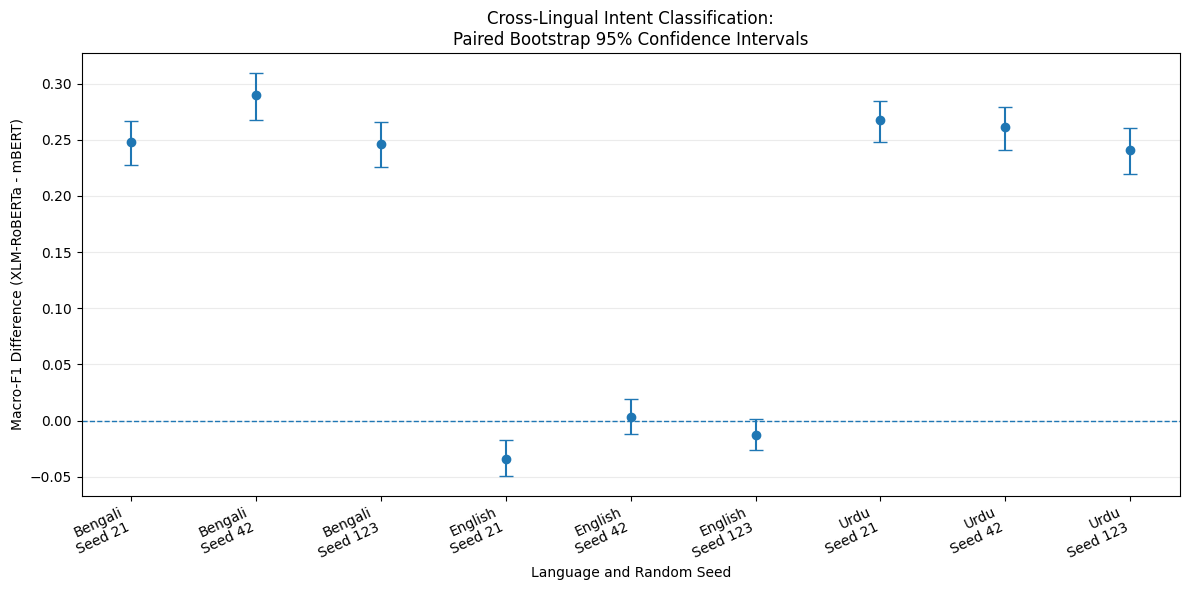


PUBLICATION-READY SUMMARY


,Language,mBERT Accuracy,XLM-R Accuracy,mBERT Macro-F1,XLM-R Macro-F1,Mean F1 Difference,Accuracy Significant Seeds (Holm)
0,English,0.8366 ± 0.0012,0.8448 ± 0.0036,0.7067 ± 0.0022,0.6922 ± 0.0173,-0.0146,0
1,Urdu,0.2606 ± 0.0148,0.5815 ± 0.0151,0.1653 ± 0.0174,0.4219 ± 0.0036,0.2565,3
2,Bengali,0.2581 ± 0.0031,0.5841 ± 0.0041,0.1701 ± 0.0157,0.4314 ± 0.0181,0.2613,3



STATISTICAL INTERPRETATION

Language: English
Holm-significant accuracy comparisons: 0/3
Seeds favoring XLM-R on macro-F1: 1/3
Positive bootstrap F1 intervals: 0/3
Negative bootstrap F1 intervals: 1/3

Language: Urdu
Holm-significant accuracy comparisons: 3/3
Seeds favoring XLM-R on macro-F1: 3/3
Positive bootstrap F1 intervals: 3/3
Negative bootstrap F1 intervals: 0/3

Language: Bengali
Holm-significant accuracy comparisons: 3/3
Seeds favoring XLM-R on macro-F1: 3/3
Positive bootstrap F1 intervals: 3/3
Negative bootstrap F1 intervals: 0/3

EXPERIMENT 7 COMPLETED SUCCESSFULLY

Files saved in: /content/drive/MyDrive/CrossLingual_AI/statistical_analysis

Generated files:
 - macro_f1_bootstrap_ci.png
 - per_seed_statistical_tests.csv
 - publication_ready_summary.csv
 - three_seed_statistical_summary.csv

Note: McNemar tests assess paired accuracy for fixed trained models. Bootstrap intervals quantify test-set uncertainty, not training-seed uncertainty.


In [9]:

# ================================================================
# EXPERIMENT 7: STATISTICAL SIGNIFICANCE + CONFIDENCE INTERVALS
# ================================================================
# Project: Cross-Lingual Conversational AI Evaluation
# Dataset: Amazon MASSIVE 1.0
# Models: mBERT vs XLM-RoBERTa
# Languages: English, Urdu, Bengali
# Seeds: 21, 42, 123
#
# Statistical methods:
# 1. Exact McNemar test for paired accuracy
# 2. Paired bootstrap 95% confidence intervals
# 3. Three-seed descriptive statistics
# 4. Holm correction for 9 McNemar tests
#
# IMPORTANT:
# - All 60 intent classes are used for macro-F1.
# - A class absent from the test set still contributes zero F1.
# - No model training is performed.
# - Existing Experiment 6 results are not modified.
# ================================================================

import os
import json
import sys
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.metrics import accuracy_score, f1_score
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

# ---------------------------------------------------------------
# STEP 1: Mount Google Drive
# ---------------------------------------------------------------

drive.mount("/content/drive")

BASE = "/content/drive/MyDrive/CrossLingual_AI"

SOURCE = os.path.join(
    BASE,
    "final_verified_results",
    "all_verified_predictions.csv"
)

CONFIG_PATH = os.path.join(
    BASE,
    "mbert_checkpoint_fixed",
    "config.json"
)

OUT = os.path.join(
    BASE,
    "statistical_analysis"
)

os.makedirs(OUT, exist_ok=True)

assert os.path.isfile(SOURCE), (
    f"Predictions file not found: {SOURCE}"
)

assert os.path.isfile(CONFIG_PATH), (
    f"Configuration file not found: {CONFIG_PATH}"
)

df = pd.read_csv(
    SOURCE,
    dtype={"ID": str}
)

print("Loaded predictions:", len(df))
print("Output directory:", OUT)

# ---------------------------------------------------------------
# STEP 2: Load ALL 60 intent classes
# ---------------------------------------------------------------
# FIX:
# The test dataset contains 59 observed intent classes.
# However, the trained classifiers have 60 output classes.
#
# We load all 60 labels from the model configuration to
# preserve the same macro-F1 definition as Experiment 6.
# ---------------------------------------------------------------

with open(
    CONFIG_PATH,
    "r",
    encoding="utf-8"
) as file:
    config = json.load(file)

id2label = {
    int(k): v
    for k, v in config["id2label"].items()
}

labels = [
    id2label[i]
    for i in range(60)
]

assert len(labels) == 60
assert len(set(labels)) == 60

observed_labels = set(
    df["True Intent"].dropna().unique()
)

missing_test_labels = sorted(
    set(labels) - observed_labels
)

print("\nINTENT CLASS VALIDATION")
print("Total classifier labels:", len(labels))
print("Observed test labels:", len(observed_labels))
print("Absent test labels:", missing_test_labels)

assert observed_labels.issubset(set(labels)), (
    "Unexpected ground-truth intent labels found."
)

assert set(
    df["Predicted Intent"].dropna().unique()
).issubset(set(labels)), (
    "Unexpected predicted intent labels found."
)

# ---------------------------------------------------------------
# STEP 3: Validate prediction dataset
# ---------------------------------------------------------------

MODELS = [
    "mBERT",
    "XLM-RoBERTa"
]

LANGUAGES = [
    "English",
    "Urdu",
    "Bengali"
]

SEEDS = [
    21,
    42,
    123
]

N_BOOTSTRAP = 2000

required_columns = {
    "Model",
    "Seed",
    "Language",
    "ID",
    "True Intent",
    "Predicted Intent"
}

assert required_columns.issubset(
    df.columns
), (
    "Missing columns: "
    f"{required_columns - set(df.columns)}"
)

assert not df[
    list(required_columns)
].isna().any().any(), (
    "Missing values detected in required columns."
)

assert not df.duplicated(
    ["Model", "Seed", "Language", "ID"]
).any(), (
    "Duplicate prediction IDs detected."
)

expected_rows = (
    len(MODELS)
    * len(SEEDS)
    * len(LANGUAGES)
    * 2974
)

assert len(df) == expected_rows, (
    f"Expected {expected_rows} rows, found {len(df)}"
)

print("\nDATASET VALIDATION PASSED")
print("Models:", MODELS)
print("Seeds:", SEEDS)
print("Languages:", LANGUAGES)
print("Bootstrap resamples:", N_BOOTSTRAP)

# ---------------------------------------------------------------
# STEP 4: Align predictions for paired comparisons
# ---------------------------------------------------------------
# The same test examples must be compared between models.
# Alignment is performed using the MASSIVE example ID.
# ---------------------------------------------------------------

def get_paired_predictions(language, seed):

    mbert = df[
        (df["Model"] == "mBERT")
        & (df["Language"] == language)
        & (df["Seed"] == seed)
    ][
        ["ID", "True Intent", "Predicted Intent"]
    ].copy()

    xlmr = df[
        (df["Model"] == "XLM-RoBERTa")
        & (df["Language"] == language)
        & (df["Seed"] == seed)
    ][
        ["ID", "True Intent", "Predicted Intent"]
    ].copy()

    assert len(mbert) == 2974, (
        f"mBERT count incorrect: {language}, {seed}"
    )

    assert len(xlmr) == 2974, (
        f"XLM-R count incorrect: {language}, {seed}"
    )

    paired = mbert.merge(
        xlmr,
        on="ID",
        suffixes=("_mbert", "_xlmr"),
        validate="one_to_one"
    )

    assert len(paired) == 2974, (
        f"Unmatched test examples: {language}, {seed}"
    )

    assert (
        paired["True Intent_mbert"]
        == paired["True Intent_xlmr"]
    ).all(), (
        "Ground-truth labels do not match."
    )

    return paired.sort_values(
        "ID"
    ).reset_index(drop=True)

# ---------------------------------------------------------------
# STEP 5: Paired bootstrap confidence intervals
# ---------------------------------------------------------------
# We sample test examples with replacement.
# Both models use the same sampled indices.
#
# Difference = XLM-RoBERTa - mBERT
#
# A positive difference favors XLM-RoBERTa.
#
# Bootstrap intervals quantify test-sample uncertainty
# conditional on the two trained models.
# ---------------------------------------------------------------

def paired_bootstrap(
    y_true,
    pred_mbert,
    pred_xlmr,
    random_seed
):

    rng = np.random.default_rng(
        random_seed
    )

    n = len(y_true)

    accuracy_diffs = np.empty(
        N_BOOTSTRAP,
        dtype=np.float64
    )

    f1_diffs = np.empty(
        N_BOOTSTRAP,
        dtype=np.float64
    )

    for b in range(N_BOOTSTRAP):

        indices = rng.integers(
            low=0,
            high=n,
            size=n
        )

        yt = y_true[indices]
        pm = pred_mbert[indices]
        px = pred_xlmr[indices]

        # Paired accuracy difference
        accuracy_diffs[b] = (
            np.mean(px == yt)
            - np.mean(pm == yt)
        )

        # Paired macro-F1 difference
        # Explicit labels=labels keeps all 60 classes.
        f1_m = f1_score(
            yt,
            pm,
            labels=labels,
            average="macro",
            zero_division=0
        )

        f1_x = f1_score(
            yt,
            px,
            labels=labels,
            average="macro",
            zero_division=0
        )

        f1_diffs[b] = f1_x - f1_m

    return {
        "Accuracy_CI_Lower": float(
            np.percentile(
                accuracy_diffs, 2.5
            )
        ),
        "Accuracy_CI_Upper": float(
            np.percentile(
                accuracy_diffs, 97.5
            )
        ),
        "Macro_F1_CI_Lower": float(
            np.percentile(
                f1_diffs, 2.5
            )
        ),
        "Macro_F1_CI_Upper": float(
            np.percentile(
                f1_diffs, 97.5
            )
        )
    }

# ---------------------------------------------------------------
# STEP 6: Run statistical tests
# ---------------------------------------------------------------

results = []

for language_index, language in enumerate(LANGUAGES):

    for seed in SEEDS:

        print(
            f"\nAnalyzing {language} | Seed {seed}"
        )

        paired = get_paired_predictions(
            language,
            seed
        )

        y_true = paired[
            "True Intent_mbert"
        ].to_numpy()

        pred_m = paired[
            "Predicted Intent_mbert"
        ].to_numpy()

        pred_x = paired[
            "Predicted Intent_xlmr"
        ].to_numpy()

        # -------------------------------------------------------
        # Calculate model performance
        # -------------------------------------------------------

        acc_m = accuracy_score(
            y_true,
            pred_m
        )

        acc_x = accuracy_score(
            y_true,
            pred_x
        )

        f1_m = f1_score(
            y_true,
            pred_m,
            labels=labels,
            average="macro",
            zero_division=0
        )

        f1_x = f1_score(
            y_true,
            pred_x,
            labels=labels,
            average="macro",
            zero_division=0
        )

        # -------------------------------------------------------
        # Construct McNemar contingency table
        # -------------------------------------------------------

        m_correct = (
            pred_m == y_true
        )

        x_correct = (
            pred_x == y_true
        )

        both_correct = int(
            np.sum(
                m_correct & x_correct
            )
        )

        mbert_only = int(
            np.sum(
                m_correct & ~x_correct
            )
        )

        xlmr_only = int(
            np.sum(
                ~m_correct & x_correct
            )
        )

        both_wrong = int(
            np.sum(
                ~m_correct & ~x_correct
            )
        )

        contingency = [
            [both_correct, mbert_only],
            [xlmr_only, both_wrong]
        ]

        # Exact McNemar test
        test = mcnemar(
            contingency,
            exact=True
        )

        # -------------------------------------------------------
        # Calculate bootstrap confidence intervals
        # -------------------------------------------------------

        bootstrap_ci = paired_bootstrap(
            y_true,
            pred_m,
            pred_x,
            random_seed=(
                2026
                + language_index * 1000
                + seed
            )
        )

        result = {
            "Language": language,
            "Seed": seed,

            "mBERT_Accuracy": acc_m,
            "XLMR_Accuracy": acc_x,
            "Accuracy_Difference": (
                acc_x - acc_m
            ),

            "mBERT_Macro_F1": f1_m,
            "XLMR_Macro_F1": f1_x,
            "Macro_F1_Difference": (
                f1_x - f1_m
            ),

            "Both_Correct": both_correct,
            "mBERT_Only_Correct": mbert_only,
            "XLMR_Only_Correct": xlmr_only,
            "Both_Wrong": both_wrong,

            "McNemar_p": float(
                test.pvalue
            ),

            **bootstrap_ci
        }

        results.append(result)

        print(
            "Accuracy difference:",
            round(
                result["Accuracy_Difference"], 4
            )
        )

        print(
            "Macro-F1 difference:",
            round(
                result["Macro_F1_Difference"], 4
            )
        )

        print(
            "McNemar p-value:",
            result["McNemar_p"]
        )

# ---------------------------------------------------------------
# STEP 7: Multiple-testing correction
# ---------------------------------------------------------------
# We performed 9 McNemar tests:
# 3 languages x 3 seeds.
#
# Holm correction controls family-wise error for this
# collection of accuracy comparisons.
# ---------------------------------------------------------------

results_df = pd.DataFrame(results)

reject, adjusted_p, _, _ = multipletests(
    results_df["McNemar_p"].to_numpy(),
    alpha=0.05,
    method="holm"
)

results_df["McNemar_Holm_p"] = adjusted_p
results_df["McNemar_Holm_Significant"] = reject

# Bootstrap CI zero-exclusion is descriptive.
# It is not adjusted for multiple comparisons.

results_df["Macro_F1_CI_Excludes_Zero"] = (
    (
        results_df["Macro_F1_CI_Lower"] > 0
    )
    |
    (
        results_df["Macro_F1_CI_Upper"] < 0
    )
)

results_df.to_csv(
    os.path.join(
        OUT,
        "per_seed_statistical_tests.csv"
    ),
    index=False
)

print("\n" + "=" * 65)
print("PER-SEED STATISTICAL RESULTS")
print("=" * 65)

display(
    results_df[
        [
            "Language",
            "Seed",
            "Accuracy_Difference",
            "Macro_F1_Difference",
            "McNemar_p",
            "McNemar_Holm_p",
            "McNemar_Holm_Significant",
            "Macro_F1_CI_Lower",
            "Macro_F1_CI_Upper"
        ]
    ].round(6)
)

# ---------------------------------------------------------------
# STEP 8: Three-seed descriptive summary
# ---------------------------------------------------------------
# These values describe variability across the 3 trained
# models per architecture.
#
# Do not interpret the bootstrap confidence intervals as
# confidence intervals across training seeds.
# ---------------------------------------------------------------

summary = results_df.groupby(
    "Language"
).agg(
    Seeds=(
        "Seed", "nunique"
    ),

    Accuracy_Difference_Mean=(
        "Accuracy_Difference", "mean"
    ),

    Accuracy_Difference_SD=(
        "Accuracy_Difference", "std"
    ),

    Macro_F1_Difference_Mean=(
        "Macro_F1_Difference", "mean"
    ),

    Macro_F1_Difference_SD=(
        "Macro_F1_Difference", "std"
    ),

    All_Seeds_XLMR_Better_Accuracy=(
        "Accuracy_Difference",
        lambda x: bool((x > 0).all())
    ),

    All_Seeds_XLMR_Better_Macro_F1=(
        "Macro_F1_Difference",
        lambda x: bool((x > 0).all())
    )
).reset_index()

summary.to_csv(
    os.path.join(
        OUT,
        "three_seed_statistical_summary.csv"
    ),
    index=False
)

print("\n" + "=" * 65)
print("THREE-SEED SUMMARY")
print("=" * 65)

display(summary.round(6))

# ---------------------------------------------------------------
# STEP 9: Plot bootstrap confidence intervals
# ---------------------------------------------------------------

plot_df = results_df.sort_values(
    ["Language", "Seed"]
).reset_index(drop=True)

positions = np.arange(
    len(plot_df)
)

means = plot_df[
    "Macro_F1_Difference"
].to_numpy()

lower_errors = (
    means
    - plot_df["Macro_F1_CI_Lower"].to_numpy()
)

upper_errors = (
    plot_df["Macro_F1_CI_Upper"].to_numpy()
    - means
)

fig, ax = plt.subplots(
    figsize=(12, 6)
)

ax.errorbar(
    positions,
    means,
    yerr=[
        lower_errors,
        upper_errors
    ],
    fmt="o",
    capsize=5,
    markersize=6
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1
)

ax.set_xticks(positions)

ax.set_xticklabels(
    [
        f"{row.Language}\nSeed {row.Seed}"
        for row in plot_df.itertuples()
    ],
    rotation=25,
    ha="right"
)

ax.set_ylabel(
    "Macro-F1 Difference (XLM-RoBERTa - mBERT)"
)

ax.set_xlabel(
    "Language and Random Seed"
)

ax.set_title(
    "Cross-Lingual Intent Classification:\n"
    "Paired Bootstrap 95% Confidence Intervals"
)

ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

figure_path = os.path.join(
    OUT,
    "macro_f1_bootstrap_ci.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ---------------------------------------------------------------
# STEP 10: Generate publication-ready summary table
# ---------------------------------------------------------------

publication_rows = []

for language in LANGUAGES:

    subset = results_df[
        results_df["Language"] == language
    ]

    publication_rows.append({
        "Language": language,

        "mBERT Accuracy": (
            f"{subset['mBERT_Accuracy'].mean():.4f} "
            f"± {subset['mBERT_Accuracy'].std():.4f}"
        ),

        "XLM-R Accuracy": (
            f"{subset['XLMR_Accuracy'].mean():.4f} "
            f"± {subset['XLMR_Accuracy'].std():.4f}"
        ),

        "mBERT Macro-F1": (
            f"{subset['mBERT_Macro_F1'].mean():.4f} "
            f"± {subset['mBERT_Macro_F1'].std():.4f}"
        ),

        "XLM-R Macro-F1": (
            f"{subset['XLMR_Macro_F1'].mean():.4f} "
            f"± {subset['XLMR_Macro_F1'].std():.4f}"
        ),

        "Mean F1 Difference": (
            subset["Macro_F1_Difference"].mean()
        ),

        "Accuracy Significant Seeds (Holm)": (
            int(
                subset[
                    "McNemar_Holm_Significant"
                ].sum()
            )
        )
    })

publication_df = pd.DataFrame(
    publication_rows
)

publication_df.to_csv(
    os.path.join(
        OUT,
        "publication_ready_summary.csv"
    ),
    index=False
)

print("\n" + "=" * 65)
print("PUBLICATION-READY SUMMARY")
print("=" * 65)

display(publication_df.round(4))

# ---------------------------------------------------------------
# STEP 11: Final interpretation
# ---------------------------------------------------------------

print("\n" + "=" * 65)
print("STATISTICAL INTERPRETATION")
print("=" * 65)

for language in LANGUAGES:

    subset = results_df[
        results_df["Language"] == language
    ]

    significant = int(
        subset["McNemar_Holm_Significant"].sum()
    )

    positive_f1 = int(
        (
            subset["Macro_F1_Difference"] > 0
        ).sum()
    )

    positive_ci = int(
        (
            subset["Macro_F1_CI_Lower"] > 0
        ).sum()
    )

    negative_ci = int(
        (
            subset["Macro_F1_CI_Upper"] < 0
        ).sum()
    )

    print(f"\nLanguage: {language}")

    print(
        "Holm-significant accuracy comparisons:",
        f"{significant}/3"
    )

    print(
        "Seeds favoring XLM-R on macro-F1:",
        f"{positive_f1}/3"
    )

    print(
        "Positive bootstrap F1 intervals:",
        f"{positive_ci}/3"
    )

    print(
        "Negative bootstrap F1 intervals:",
        f"{negative_ci}/3"
    )

print("\n" + "=" * 65)
print("EXPERIMENT 7 COMPLETED SUCCESSFULLY")
print("=" * 65)

print("\nFiles saved in:", OUT)

print("\nGenerated files:")
for filename in sorted(os.listdir(OUT)):
    print(" -", filename)

print(
    "\nNote: McNemar tests assess paired accuracy for fixed "
    "trained models. Bootstrap intervals quantify test-set "
    "uncertainty, not training-seed uncertainty."
)
